In [15]:
import os
import sys
import cv2
import math
import random
import json
import time
import numpy as np
import pandas as pd
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from scipy.ndimage import map_coordinates
import tkinter as tk
from tkinter import ttk
from tkinter import filedialog, messagebox
from PIL import Image, ImageDraw, ImageTk
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
from brain_registration import BrainRegistration
import csv

In [16]:
brain_reg = BrainRegistration(voxel = 'nrrd')

In [17]:
#总控制器 MainApp
class MainApp:
    def __init__(self, root):
        self.root = root
        self.root.title("Brain Image Tool")
        self.root.state("zoomed")

        self.current_page = None
        self.show_home()

    def clear_page(self):
        if self.current_page is not None:
            self.current_page.destroy()

    def show_home(self):
        self.clear_page()
        self.current_page = HomePage(self.root, self)
        self.current_page.pack(fill=tk.BOTH, expand=True)

    def show_brain_registration(self):
        self.clear_page()
        self.current_page = BrainRegistrationApp(self.root, self)
        self.current_page.pack(fill=tk.BOTH, expand=True)

    def show_combined_app(self):
        self.clear_page()
        self.current_page = CombinedApp(self.root, self)
        self.current_page.pack(fill=tk.BOTH, expand=True)

In [18]:
#首页
class HomePage(tk.Frame):
    def __init__(self, root, controller):
        super().__init__(root)
        self.controller = controller

        title = tk.Label(
            self,
            text="Welcome to GPS-seq Platform",
            font=("Arial", 24, "bold")
        )
        title.pack(pady=30)

        content_frame = tk.Frame(self)
        content_frame.pack(fill=tk.BOTH, expand=True, padx=40, pady=20)

        # 左栏
        left_frame = tk.Frame(content_frame, bd=2, relief=tk.GROOVE, padx=20, pady=20)
        left_frame.pack(side=tk.LEFT, fill=tk.BOTH, expand=True, padx=20, pady=20)

        left_title = tk.Label(left_frame, text="GPS-seq BrainRegistration", font=("Arial", 18, "bold"))
        left_title.pack(pady=15)

        # 插入左侧图片
        brain_img = Image.open("e:\\benchmark\\new_brain_registration_group_ConvNext\\brain_registration_group\\model.png")
        brain_img = brain_img.resize((540, 360))
        self.brain_photo = ImageTk.PhotoImage(brain_img, master=self)
        brain_label = tk.Label(left_frame, image=self.brain_photo)
        brain_label.pack(pady=10)

        left_desc = tk.Label(
            left_frame,
            text=(
                "This module is used for mouse brain registration.\n\n"
                "Step 1:\n"
                "- Auto registration by model\n\n"
                "Step 2:\n"
                "- Manual refine"
            ),
            font=("Arial", 13, "bold"),
            justify=tk.LEFT
        )
        left_desc.pack(pady=20)

        left_btn = tk.Button(
            left_frame,
            text="Enter BrainRegistration",
            font=("Arial", 14, "bold"),
            bg="#2196F3",
            fg="white",
            padx=20,
            pady=10,
            command=self.controller.show_brain_registration
        )
        left_btn.pack(pady=20)

        # 右栏
        right_frame = tk.Frame(content_frame, bd=2, relief=tk.GROOVE, padx=20, pady=20)
        right_frame.pack(side=tk.RIGHT, fill=tk.BOTH, expand=True, padx=20, pady=20)

        right_title = tk.Label(right_frame, text="Calibration + XML Generation", font=("Arial", 18, "bold"))
        right_title.pack(pady=15)

        # 插入右侧图片
        workflow_img = Image.open("e:\\benchmark\\new_brain_registration_group_ConvNext\\brain_registration_group\\workflow.png")
        workflow_img = workflow_img.resize((540, 360))
        self.workflow_photo = ImageTk.PhotoImage(workflow_img, master=self)
        workflow_label = tk.Label(right_frame, image=self.workflow_photo)
        workflow_label.pack(pady=10)

        right_desc = tk.Label(
            right_frame,
            text=(
                "This module contains a complete two-step workflow.\n\n"
                "Step 1:\n"
                "- Select calibration points from image\n\n"
                "Step 2:\n"
                "- Generate XML for LCM cutting workflow"
            ),
            font=("Arial", 13, "bold"),
            justify=tk.LEFT
        )
        right_desc.pack(pady=20)

        right_btn = tk.Button(
            right_frame,
            text="Enter Combined Workflow",
            font=("Arial", 14, "bold"),
            bg="#4CAF50",
            fg="white",
            padx=20,
            pady=10,
            command=self.controller.show_combined_app
        )
        right_btn.pack(pady=20)

In [19]:
#Brain registration
class BrainRegistrationApp(tk.Frame):
    def __init__(self, root, controller):
        super().__init__(root)
        self.controller = controller

        title = tk.Label(self, text="Brain Registration Tools", font=("Arial", 18, "bold"))
        title.pack(pady=10)

        back_btn = tk.Button(
            self,
            text="Back to Home",
            bg="#008CBA",
            font=("Arial", 12, "bold"),
            command=self.controller.show_home
        )
        back_btn.pack(pady=10)

        # 创建主 Frame
        content_frame = tk.Frame(self)
        content_frame.pack(fill=tk.BOTH, expand=True)

        # 左右分栏
        self.frame1 = tk.Frame(content_frame, bd=2, relief=tk.GROOVE)
        self.frame1.pack(side=tk.LEFT, padx=2, pady=20, fill=tk.BOTH, expand=False)  # 不使用 expand 使得左侧为固定宽度

        self.frame2 = tk.Frame(content_frame, bd=2, relief=tk.GROOVE)
        self.frame2.pack(side=tk.RIGHT, padx=20, pady=20, fill=tk.BOTH, expand=True)  # 使用 expand 使得右侧分栏占用剩余空间

        # 标题
        self.step1_label = tk.Label(self.frame1, text="Step 1. Auto Registration", font=("Arial", 15, "bold"))
        self.step1_label.pack(pady=10)

        self.step2_label = tk.Label(self.frame2, text="Step 2. Manual Refine", font=("Arial", 15, "bold"))
        self.step2_label.pack(pady=10)

        # 子模块
        self.image_cropper = AutoBrainRegistrationApp(self.frame1, self)
        self.brain_region_processor = ManualrefineApp(self.frame2, self)
        
    def pass_files_to_manual_refine(self, input_file, output_file, output_path):
        """接收 AutoBrainRegistrationApp 传递的文件路径，并传递给 ManualrefineApp"""
        self.brain_region_processor.load_files(input_file, output_file, output_path)


In [20]:
#1. Auto Registration
class AutoBrainRegistrationApp:
    def __init__(self, root, controller):
        self.root = root
        self.controller = controller
        
        # 创建主 Frame
        self.main_frame = tk.Frame(self.root)
        self.main_frame.pack(fill="both", expand=True)

        # 参数设置 Frame
        self.settings_frame = tk.Frame(self.main_frame, width=400, padx=10, pady=10, relief="sunken", borderwidth=2)
        self.settings_frame.pack(side="left", fill="both", expand=True)

        # 参数设置区域（包括 param_frame）
        self.param_frame = tk.Frame(self.settings_frame)
        self.param_frame.pack(side="top", fill="both", expand=False)

        # 图片展示区域
        self.image_display_frame = tk.Frame(self.settings_frame)
        self.image_display_frame.pack(side="bottom", fill="both", expand=True)

        # 初始化变量
        self.brain_region_img_path = tk.StringVar()
        self.output_dir = tk.StringVar()
        self.brain_region = tk.StringVar()
        self.section_layer = tk.StringVar()
        self.save_temp = tk.BooleanVar(value=False)
        self.temp_result = tk.BooleanVar(value=False)
        self.enlarge = tk.BooleanVar(value=False)
        self.display_mode = tk.StringVar(value="Allen")
        self.brain_state = tk.StringVar(value="damaged")
        self.angle_integration = tk.BooleanVar(value=False)

        # 加载脑区列表（确保文件路径正确）
        self.brain_region_options = self.load_brain_region_options("e:\\benchmark\\new_brain_registration_group_ConvNext\\brain_registration_group\\brain_registration\\metadata\\Allen_nii\\brain_region_abbr.csv")

        # 创建 UI 组件
        self.create_widgets()

    def create_widgets(self):
        """创建 Tkinter 左侧 UI 组件（参数设置，居中对齐）"""

        # **选择脑区图像（居中）**
        tk.Label(self.param_frame, text="Select brain image/folder:", font=("Arial", 12, "bold")).pack(pady=2, padx=50, anchor="w")
        
        input_frame = tk.Frame(self.param_frame)
        input_frame.pack(pady=5, padx=50, fill="x")

        tk.Entry(input_frame, textvariable=self.brain_region_img_path, width=40, font=("Arial", 12, "bold"), bd=3, relief=tk.SUNKEN).pack(side="left", padx=5, ipady=6)
        
        btn_frame = tk.Frame(input_frame)
        btn_frame.pack(side="left", padx=10)

        tk.Button(btn_frame, text="Select Image", command=self.load_brain_image, font=("Arial", 12, "bold"), relief=tk.RAISED, bg="#4CAF50", fg="white", padx=10, pady=4, borderwidth=3, cursor="hand2").pack(side="left", padx=2)
        tk.Button(btn_frame, text="Select Folder", command=self.load_brain_folder, font=("Arial", 12, "bold"), relief=tk.RAISED, bg="#4CAF50", fg="white", padx=10, pady=4, borderwidth=3, cursor="hand2").pack(side="left", padx=2)

        # **选择输出目录（居中）**
        tk.Label(self.param_frame, text="Select output folder:", font=("Arial", 12, "bold")).pack(pady=2, padx=50, anchor="w")

        output_frame = tk.Frame(self.param_frame)
        output_frame.pack(pady=5, padx=50, fill="x")

        tk.Entry(output_frame, textvariable=self.output_dir, width=40, font=("Arial", 12, "bold"), bd=3, relief=tk.SUNKEN).pack(side="left", padx=5, ipady=6)
        tk.Button(output_frame, text="Select", command=self.select_output_dir, font=("Arial", 12, "bold"), relief=tk.RAISED, bg="#4CAF50", fg="white", padx=10, pady=4, borderwidth=3, cursor="hand2").pack(side="left", padx=10)


        # **Brain region 和 Section layer 同一行（居中）**
        section_frame = tk.Frame(self.param_frame)
        section_frame.pack(pady=5, padx=40, anchor="w")

        tk.Label(section_frame, text="Brain region:", font=("Arial", 12, "bold")).pack(side="left", padx=5, pady=2)
         # 输入框
        self.brain_region_entry = tk.Entry(section_frame, textvariable=self.brain_region, width=15, font=("Arial", 12), bd=2, relief=tk.SUNKEN)
        self.brain_region_entry.pack(side="left", padx=5, pady=2)
        self.brain_region_entry.bind('<KeyRelease>', self.update_brain_region_options)

        # 添加下拉按钮
        self.dropdown_button = tk.Button(section_frame, text="▼", font=("Arial", 10, "bold"), command=self.show_all_brain_regions, width=2, relief=tk.RAISED)
        self.dropdown_button.pack(side="left")

        # 下拉框（初始隐藏）
        self.brain_region_listbox = tk.Listbox(self.root, width=25, height=5, font=("Arial", 12))
        self.brain_region_listbox.place_forget()
        self.brain_region_listbox.bind('<Button-1>', self.select_brain_region)

        
        # Section layer 标签
        tk.Label(section_frame, text="Manual Section layer:", font=("Arial", 12, "bold")).pack(side="left", padx=5, pady=2)

        # 输入框，初始为不可编辑（disabled状态）
        self.section_layer_entry = tk.Entry(section_frame, textvariable=self.section_layer, width=15, font=("Arial", 12), bd=2, relief=tk.SUNKEN, state="disabled")
        self.section_layer_entry.pack(side="left", padx=5, pady=2)

        # Checkbutton，点击后切换输入框的状态
        self.enable_var = tk.BooleanVar(value=False)  # 默认值为 False，表示不可编辑
        enable_checkbutton = tk.Checkbutton(
            section_frame, 
            variable=self.enable_var, 
            command=self.toggle_edit,  # 绑定 command 触发事件
            font=("Arial", 12, "bold")
        )
        enable_checkbutton.pack(side="left", padx=5, pady=2)
        
        

        # **Save temp result 和 Show temp result 同一行（居中）**
        option_frame1 = tk.Frame(self.param_frame)
        option_frame1.pack(pady=10, padx=180, anchor="w")

        tk.Checkbutton(option_frame1, text="Save temp result", variable=self.save_temp, font=("Arial", 12, "bold")).pack(side="left", padx=10)
        tk.Checkbutton(option_frame1, text="Enlarge brain", variable=self.enlarge, font=("Arial", 12, "bold")).pack(side="left", padx=10)
        tk.Checkbutton(option_frame1, text="Angle integration", variable=self.angle_integration, font=("Arial", 12, "bold")).pack(side="left")


        # **Display mode 和 Brain state 在同一行**
        display_mode_frame = tk.Frame(self.param_frame)
        display_mode_frame.pack(pady=10, padx=180, anchor="w")

        # Display mode label 和 OptionMenu
        tk.Label(display_mode_frame, text="Display mode:", font=("Arial", 12, "bold")).pack(side="left", padx=5)

        option_menu = tk.OptionMenu(display_mode_frame, self.display_mode, "block", "line", "Allen")
        option_menu.config(
            font=("Arial", 12, "bold"),  # 更大的字体
            bg="#f0f0f0",  # 淡灰色背景
            fg="black",  # 黑色字体
            relief=tk.GROOVE,  # 更立体的外观
            highlightthickness=0,  # 去除边框
            padx=10, pady=5,  # 增加内边距
        )
        option_menu.pack(side="left", padx=5)

        # Brain state label 和 OptionMenu
        tk.Label(display_mode_frame, text="Brain state:", font=("Arial", 12, "bold")).pack(side="left", padx=10)

        option_menu2 = tk.OptionMenu(display_mode_frame, self.brain_state, "complete", "damaged")
        option_menu2.config(
            font=("Arial", 12, "bold"),  # 更大的字体
            bg="#f0f0f0",  # 淡灰色背景
            fg="black",  # 黑色字体
            relief=tk.GROOVE,  # 更立体的外观
            highlightthickness=0,  # 去除边框
            padx=10, pady=5,  # 增加内边距
        )
        option_menu2.pack(side="left", padx=5)


        # **运行按钮（居中）**
        self.run_button = tk.Button(self.param_frame, text="Run registration", command=self.run_registration, bg="#2196F3", fg="white", font=("Arial", 12, "bold"), relief=tk.RAISED, padx=40, pady=6, borderwidth=3, cursor="hand2")
        self.run_button.pack(pady=10, padx=300, anchor="w")

    def load_brain_image(self):
        """选择脑区图像"""
        file_path = filedialog.askopenfilename(filetypes=[("Image files", "*.png;*.jpg;*.jpeg")])
        if file_path:
            self.brain_region_img_path.set(file_path)

    def load_brain_folder(self):
        """选择一个文件夹作为输入"""
        folder_path = filedialog.askdirectory()
        if folder_path:
            self.brain_region_img_path.set(folder_path)

    def select_output_dir(self):
        """选择输出目录"""
        dir_path = filedialog.askdirectory()
        if dir_path:
            self.output_dir.set(dir_path)

    
    def update_brain_region_options(self, event=None):
        """根据输入动态更新下拉选项，支持逗号分隔多脑区输入"""
        input_text = self.brain_region.get()

        # 整个输入框为空，隐藏下拉框
        if not input_text.strip():
            self.brain_region_listbox.place_forget()
            return

        # 只针对最后一个逗号后的片段做联想
        current_part = input_text.split(",")[-1].strip()

        # 如果最后一段为空（例如刚输入完逗号），隐藏下拉框，等待继续输入
        if not current_part:
            self.brain_region_listbox.place_forget()
            return

        # 匹配候选
        filtered_options = [
            opt for opt in self.brain_region_options
            if current_part.lower() in opt.lower()
        ]

        # 计算输入框位置
        entry_x = self.brain_region_entry.winfo_rootx()
        entry_y = self.brain_region_entry.winfo_rooty() + self.brain_region_entry.winfo_height()

        if filtered_options:
            self.brain_region_listbox.delete(0, tk.END)
            for option in filtered_options:
                self.brain_region_listbox.insert(tk.END, option)

            self.brain_region_listbox.place(
                x=entry_x,
                y=entry_y,
                width=self.brain_region_entry.winfo_width()
            )
        else:
            self.brain_region_listbox.place_forget()


    def select_brain_region(self, event):
        """选择联想项后，仅替换最后一个逗号后的片段"""
        selection = self.brain_region_listbox.curselection()
        if not selection:
            return

        selected_option = self.brain_region_listbox.get(selection[0])
        current_text = self.brain_region.get()

        # 如果已有逗号，只替换最后一段
        if "," in current_text:
            parts = current_text.split(",")
            parts[-1] = selected_option
            new_text = ",".join(part.strip() for part in parts if part.strip())
        else:
            new_text = selected_option

        self.brain_region.set(new_text)
        self.brain_region_listbox.place_forget()
        self.brain_region_entry.icursor(tk.END)  # 光标移到末尾

        
    def load_brain_region_options(self, filepath):
        options = []
        try:
            with open(filepath, newline='', encoding='utf-8') as csvfile:
                reader = csv.reader(csvfile)
                for row in reader:
                    if row:
                        options.append(row[0].strip())
        except Exception as e:
            print(f"Error loading brain region list: {e}")
        return options

    def show_all_brain_regions(self):
        """显示或隐藏所有可选的脑区选项"""
        if self.brain_region_listbox.winfo_ismapped():  # 检查 Listbox 是否已显示
            self.brain_region_listbox.place_forget()  # 隐藏 Listbox
        else:
            self.brain_region_listbox.delete(0, tk.END)  # 清空现有列表
            for option in self.brain_region_options:
                self.brain_region_listbox.insert(tk.END, option)

            # 计算输入框的位置
            entry_x = self.brain_region_entry.winfo_rootx()
            entry_y = self.brain_region_entry.winfo_rooty() + self.brain_region_entry.winfo_height()

            # 重新显示 Listbox，确保位置正确
            self.brain_region_listbox.place(x=entry_x, y=entry_y, width=self.brain_region_entry.winfo_width())

    def run_registration(self):
        start_time = time.time()  # 记录开始时间
        """执行脑区注册任务"""
        raw_image_path = self.brain_region_img_path.get()
        output_dir = self.output_dir.get()

        if not raw_image_path or not output_dir:
            messagebox.showerror("错误", "请先选择脑区图像和输出目录！")
            return

        is_directory = os.path.isdir(raw_image_path)
        group_value = is_directory  # 如果是文件夹，则 True，否则 False

        brain_region_value = self.brain_region.get().strip()
        if brain_region_value:
            brain_region_value = ",".join(
                part.strip() for part in brain_region_value.split(",") if part.strip()
            )
        else:
            brain_region_value = None

        try:
            brain_reg.mouse_brain_registration(
                raw_image_path,
                output_dir,
                group=group_value,
                section_layer=self.section_layer.get() if self.section_layer.get() else None,
                brain_region=brain_region_value,
                save_temp=self.save_temp.get(),
                temp_result=False,
                display_mode=(self.display_mode.get(), "#603c87"),
                enlarge=self.enlarge.get(),
                angle_integration=self.angle_integration.get()
            )
            elapsed_time = time.time() - start_time  # 计算耗时
            messagebox.showinfo("成功", f"图像处理完成！\n耗时: {elapsed_time:.2f} 秒")
            
            self.input_file = raw_image_path  # 输入文件路径（原图像）
            self.output_file = os.path.join(output_dir, "resized_transformed_annotation.png")  # 输出文件路径（处理后的文件）
            self.output_path = output_dir

            # 配准完成后将文件路径传递给 controller（这里的 controller 即 BrainRegistrationApp）
            self.controller.pass_files_to_manual_refine(self.input_file, self.output_file, self.output_path)

            # **创建滚动区域**
            self.create_scrollable_area()

            if group_value:
                for sub_dir in sorted(os.listdir(output_dir)):
                    sub_dir_path = os.path.join(output_dir, sub_dir)
                    if os.path.isdir(sub_dir_path):
                        self.display_images(sub_dir_path, brain_region_value)
            else:
                self.display_images(output_dir, brain_region_value)

            self.scrollable_canvas.update_idletasks()
            self.scrollable_canvas.config(scrollregion=self.scrollable_canvas.bbox("all"))
            
            

        except Exception as e:
            messagebox.showerror("错误", str(e))

    def create_scrollable_area(self):
        """创建带有滚动条的 Canvas 以支持图片滚动查看"""
        for widget in self.image_display_frame.winfo_children():  # 放到左侧的 image_display_frame
            widget.destroy()

        self.scrollable_canvas = tk.Canvas(self.image_display_frame, width=600, height=300)
        self.scrollbar = tk.Scrollbar(self.image_display_frame, orient="vertical", command=self.scrollable_canvas.yview)

        self.scroll_frame = tk.Frame(self.scrollable_canvas)
        self.scroll_frame.bind("<Configure>", lambda e: self.scrollable_canvas.configure(scrollregion=self.scrollable_canvas.bbox("all")))

        self.window = self.scrollable_canvas.create_window((0, 0), window=self.scroll_frame, anchor="nw")

        self.scrollable_canvas.configure(yscrollcommand=self.scrollbar.set)

        self.scrollable_canvas.pack(side="left", fill="both", expand=True)
        self.scrollbar.pack(side="right", fill="y")

    def display_images(self, folder_path, brain_region_value):
        total_img_path = os.path.join(folder_path, "Total_brain_registration.png")
        folder_name = os.path.basename(folder_path)

        frame = tk.Frame(self.scroll_frame)
        frame.pack(pady=15, fill="x")

        # 标题
        title_label = tk.Label(frame, text=folder_name, font=("Arial", 12, "bold"))
        title_label.pack(anchor="n", pady=5)

        # 用来装图片
        container_frame = tk.Frame(frame)
        container_frame.pack(anchor="center")

        img_width, img_height = 400, 300
        img_displayed = False

        # 先把所有需要显示的图片整理到一个列表里
        image_items = []

        # 总图
        if os.path.exists(total_img_path):
            image_items.append(("Total Brain", total_img_path))

        # brain region 图（支持多个）
        if brain_region_value:
            brain_regions = [
                region.strip() for region in brain_region_value.split(",") if region.strip()
            ]

            for region in brain_regions:
                region_img_path = os.path.join(folder_path, f"{region}_registration.png")
                if os.path.exists(region_img_path):
                    image_items.append((region, region_img_path))

        # 每行显示2个
        for index, (label_text, img_path) in enumerate(image_items):
            row = index // 2
            col = index % 2

            item_frame = tk.Frame(container_frame)
            item_frame.grid(row=row, column=col, padx=10, pady=10)

            label = tk.Label(item_frame, text=label_text, font=("Arial", 10, "bold"))
            label.pack()

            img = Image.open(img_path).resize((img_width, img_height), Image.LANCZOS)
            img_tk = ImageTk.PhotoImage(img)

            canvas = tk.Canvas(item_frame, width=img_width, height=img_height)
            canvas.pack()
            canvas.create_image(img_width // 2, img_height // 2, image=img_tk)
            canvas.image = img_tk

            img_displayed = True

        if not img_displayed:
            title_label.config(fg="red")


    def toggle_edit(self):
        """根据 Checkbutton 的选中状态切换输入框的编辑状态"""
        if self.enable_var.get():  # 如果 Checkbutton 被选中
            self.section_layer_entry.config(state="normal")  # 可编辑
        else:
            self.section_layer_entry.config(state="disabled")  # 不可编辑

In [21]:
#2. Manual Refine
class TPS2D:
    def __init__(self, src_pts, dst_pts, reg=1e-3):
        self.src_pts = np.asarray(src_pts, dtype=np.float64)
        self.dst_pts = np.asarray(dst_pts, dtype=np.float64)
        self.reg = reg
        self.n = len(self.src_pts)

        if self.n < 3:
            raise ValueError("TPS requires at least 3 landmarks.")

        self._fit()

    @staticmethod
    def _kernel(r2):
        eps = 1e-8
        return r2 * np.log(r2 + eps)

    def _fit(self):
        n = self.n
        P = self.src_pts  # (n, 2)

        diff = P[:, None, :] - P[None, :, :]
        r2 = np.sum(diff ** 2, axis=2)
        K = self._kernel(r2)
        K += np.eye(n) * self.reg

        O = np.ones((n, 1))
        X = P[:, 0:1]
        Y = P[:, 1:2]

        A = np.block([
            [K, O, X, Y],
            [O.T, np.zeros((1, 3))],
            [X.T, np.zeros((1, 3))],
            [Y.T, np.zeros((1, 3))]
        ])

        vx = np.concatenate([self.dst_pts[:, 0], np.zeros(3)])
        vy = np.concatenate([self.dst_pts[:, 1], np.zeros(3)])

        params_x = np.linalg.solve(A, vx)
        params_y = np.linalg.solve(A, vy)

        self.w_x = params_x[:n]
        self.a_x = params_x[n:]

        self.w_y = params_y[:n]
        self.a_y = params_y[n:]

    def transform(self, pts):
        pts = np.asarray(pts, dtype=np.float64)  # (m, 2)
        diff = pts[:, None, :] - self.src_pts[None, :, :]
        r2 = np.sum(diff ** 2, axis=2)
        U = self._kernel(r2)

        x = pts[:, 0]
        y = pts[:, 1]

        fx = U @ self.w_x + self.a_x[0] + self.a_x[1] * x + self.a_x[2] * y
        fy = U @ self.w_y + self.a_y[0] + self.a_y[1] * x + self.a_y[2] * y

        return np.stack([fx, fy], axis=1)

class ManualrefineApp:
    def __init__(self, root, controller):
        self.root = root
        self.controller = controller
        
        self.input_file = None
        self.output_file = None
        self.output_path = None
        
        self.fixed_pil = None
        self.moving_pil = None
        self.fixed_np = None
        self.moving_np = None

        self.fixed_tk = None
        self.moving_tk = None

        self.fixed_scale = 1.0
        self.moving_scale = 1.0

        self.fixed_canvas = None
        self.moving_canvas = None

        self.fixed_canvas_img_id = None
        self.moving_canvas_img_id = None
        
        self.latest_mapping = None
        self.latest_disp = None

        # landmarks:
        # [{"id":0, "fixed":[x,y], "moving":[x,y]}]
        self.landmarks = []
        self.next_landmark_id = 0

        # canvas item -> (pair_id, side)
        self.fixed_item_to_landmark = {}
        self.moving_item_to_landmark = {}

        # drag state
        self.dragging = None  # (pair_id, side, canvas_name)
        
        
        
        
        
    def load_files(self, input_file, output_file, output_path):
        self.input_file = input_file
        self.output_file = output_file
        self.output_path = output_path
        
        self.output_dir = os.path.join(self.output_path, "manual_refine_output")
        os.makedirs(self.output_dir, exist_ok=True)
        
        self.display_files()
        
    def display_files(self):
        for widget in self.root.winfo_children():
            widget.destroy()

        print(f"Loaded Input File (fixed): {self.input_file}")
        print(f"Loaded Output File (moving): {self.output_file}")

        if not self.input_file or not self.output_file:
            messagebox.showerror("Error", "Please provide both fixed and moving image.")
            return

        try:
            self.fixed_pil = Image.open(self.input_file).convert("RGB")
            self.moving_pil = Image.open(self.output_file).convert("RGB")
            self.fixed_np = np.array(self.fixed_pil)
            self.moving_np = np.array(self.moving_pil)
        except Exception as e:
            messagebox.showerror("Error", f"Error loading images: {e}")
            return

        # ---------- Top controls ----------
        top_controls = tk.Frame(self.root)
        top_controls.pack(side=tk.TOP, fill=tk.X, pady=(8, 4))

        button_row = tk.Frame(top_controls)
        button_row.pack(anchor="center")

        btn_style = {
            "font": ("Arial", 12, "bold"),
            "relief": tk.RAISED,
            "bg": "#4CAF50",
            "fg": "white",
            "padx": 10,
            "pady": 4,
            "borderwidth": 3,
            "cursor": "hand2"
        }

        tk.Button(
            button_row,
            text="Clear landmarks",
            command=self.clear_landmarks,
            **btn_style
        ).pack(side=tk.LEFT, padx=6)

        tk.Button(
            button_row,
            text="Delete last landmark",
            command=self.delete_last_landmark,
            **btn_style
        ).pack(side=tk.LEFT, padx=6)

        tk.Button(
            button_row,
            text="Save landmarks",
            command=self.save_landmarks,
            **btn_style
        ).pack(side=tk.LEFT, padx=6)

        self.status_label = tk.Label(
            top_controls,
            text="Click on either image to add paired landmarks.",
            font=("Arial", 11)
        )
        self.status_label.pack(pady=(8, 0))

        # ---------- Image area ----------
        content = tk.Frame(self.root)
        content.pack(fill=tk.BOTH, expand=True)

        top_frame = tk.Frame(content)
        top_frame.pack(side=tk.TOP, pady=5)

        bottom_frame = tk.Frame(content)
        bottom_frame.pack(side=tk.TOP, pady=5)

        tk.Label(top_frame, text="Fixed Image").pack(pady=(0, 3))
        tk.Label(bottom_frame, text="Moving Image").pack(pady=(0, 3))

        fixed_w, fixed_h, self.fixed_scale = self._compute_display_size(self.fixed_pil, max_size=(450, 400))
        moving_w, moving_h, self.moving_scale = self._compute_display_size(self.moving_pil, max_size=(450, 400))

        self.fixed_canvas = tk.Canvas(top_frame, width=fixed_w, height=fixed_h, highlightthickness=0, bd=0)
        self.fixed_canvas.pack()

        self.moving_canvas = tk.Canvas(bottom_frame, width=moving_w, height=moving_h, highlightthickness=0, bd=0)
        self.moving_canvas.pack()
        
        self.image_states = {
            "fixed": {
                "pil": self.fixed_pil,
                "canvas": self.fixed_canvas,
                "base_w": fixed_w,
                "base_h": fixed_h,
                "zoom": 1.0,
                "max_zoom": 3,
                "offset_x": 0,
                "offset_y": 0,
                "photo": None,
                "image_id": None,
                "drag_last_x": None,
                "drag_last_y": None,
                "press_x": None,
                "press_y": None,
                "is_panning": False,
            },
            "moving": {
                "pil": self.moving_pil,
                "canvas": self.moving_canvas,
                "base_w": moving_w,
                "base_h": moving_h,
                "zoom": 1.0,
                "max_zoom": 3,
                "offset_x": 0,
                "offset_y": 0,
                "photo": None,
                "image_id": None,
                "drag_last_x": None,
                "drag_last_y": None,
                "press_x": None,
                "press_y": None,
                "is_panning": False,
            }
        }

        self._render_canvas_image("fixed")
        self._render_canvas_image("moving")
        self._bind_canvas_events()

        # ---------- Bottom controls ----------
        bottom_controls = tk.Frame(self.root)
        bottom_controls.pack(side=tk.TOP, fill=tk.X, pady=(8, 10))

        # 创建包含两个按钮的 Frame，并将它们分布在左右
        button_frame = tk.Frame(bottom_controls)
        button_frame.pack(side=tk.TOP, fill=tk.X, padx=10)

        # Run TPS Warp 按钮（左侧）
        self.run_tps_warp_button = tk.Button(
            button_frame,
            text="Run TPS Warp",
            command=self.run_tps_warp,
            font=("Arial", 12, "bold"),
            relief=tk.RAISED,
            bg="#2196F3",
            fg="white",
            padx=12,
            pady=5,
            borderwidth=3,
            cursor="hand2"
        )
        self.run_tps_warp_button.pack(side="left", padx=(0, 10))  # 左边按钮

        # Transform Other Mask 按钮（右侧）
        self.transform_other_mask_button = tk.Button(
            button_frame,
            text="Transform Other Mask",
            command=self.transform_other_mask,  # 调用变换掩码的功能
            font=("Arial", 12, "bold"),
            bg="grey",  # 初始状态为灰色
            fg="white",
            padx=12,
            pady=5,
            relief=tk.RAISED,
            borderwidth=3,
            state=tk.DISABLED  # 初始不可用
        )
        self.transform_other_mask_button.pack(side="right", padx=(10, 0))  # 右边按钮

        
    def _compute_display_size(self, pil_image, max_size=(450, 400)):
        w, h = pil_image.size
        max_w, max_h = max_size
        scale = min(max_w / w, max_h / h)
        new_w = int(w * scale)
        new_h = int(h * scale)
        return new_w, new_h, scale

    def _display_image_on_canvas(self, which):
        if which == "fixed":
            pil_img = self.fixed_pil
            canvas = self.fixed_canvas
        else:
            pil_img = self.moving_pil
            canvas = self.moving_canvas

        new_w, new_h, scale = self._compute_display_size(pil_img, max_size=(450, 400))
        resized = pil_img.resize((new_w, new_h), Image.LANCZOS)
        tk_img = ImageTk.PhotoImage(resized)
        
        canvas.config(width=new_w, height=new_h)
        canvas.delete("all")
        img_id = canvas.create_image(0, 0, anchor="nw", image=tk_img)

        if which == "fixed":
            self.fixed_tk = tk_img
            self.fixed_scale = scale
            self.fixed_canvas_img_id = img_id
        else:
            self.moving_tk = tk_img
            self.moving_scale = scale
            self.moving_canvas_img_id = img_id

        self._redraw_landmarks()

    def _bind_canvas_events(self):
        for which in ("fixed", "moving"):
            canvas = self.image_states[which]["canvas"]

            # 左键统一入口：点击 / 拖 landmark / 拖动画面
            canvas.bind("<ButtonPress-1>", lambda e, w=which: self._on_left_press(w, e))
            canvas.bind("<B1-Motion>", lambda e, w=which: self._on_left_motion(w, e))
            canvas.bind("<ButtonRelease-1>", lambda e, w=which: self._on_left_release(w, e))

            # 滚轮缩放
            canvas.bind("<MouseWheel>", lambda e, w=which: self._on_mousewheel(w, e))
            canvas.bind("<Button-4>", lambda e, w=which: self._on_mousewheel_linux_up(w, e))
            canvas.bind("<Button-5>", lambda e, w=which: self._on_mousewheel_linux_down(w, e))


    def canvas_to_image(self, x, y, which):
        state = self.image_states[which]
        base_scale = self.fixed_scale if which == "fixed" else self.moving_scale

        # 先减去平移偏移
        disp_x = x - state["offset_x"]
        disp_y = y - state["offset_y"]

        # 再除以 zoom，回到“初始显示尺寸坐标”
        base_x = disp_x / state["zoom"]
        base_y = disp_y / state["zoom"]

        # 再除以初始显示比例，回到原图坐标
        return base_x / base_scale, base_y / base_scale


    def image_to_canvas(self, x, y, which):
        state = self.image_states[which]
        base_scale = self.fixed_scale if which == "fixed" else self.moving_scale

        base_x = x * base_scale
        base_y = y * base_scale

        canvas_x = base_x * state["zoom"] + state["offset_x"]
        canvas_y = base_y * state["zoom"] + state["offset_y"]
        return canvas_x, canvas_y


    def _find_nearby_landmark(self, event, which, radius=8):
        canvas = self.fixed_canvas if which == "fixed" else self.moving_canvas
        item_map = self.fixed_item_to_landmark if which == "fixed" else self.moving_item_to_landmark

        items = canvas.find_overlapping(
        event.x - radius, event.y - radius,
        event.x + radius, event.y + radius)
        
        for item in items:
            if item in item_map:
                return item_map[item]
        return None

    def _on_left_press(self, which, event):
        state = self.image_states[which]

        state["press_x"] = event.x
        state["press_y"] = event.y
        state["drag_last_x"] = event.x
        state["drag_last_y"] = event.y
        state["is_panning"] = False

        # 先判断是不是点中了已有 landmark
        found = self._find_nearby_landmark(event, which)
        if found is not None:
            pair_id, side = found
            self.dragging = (pair_id, side, which)
            return

        self.dragging = None


    def _on_left_motion(self, which, event):
        state = self.image_states[which]

        # 1. 优先处理 landmark 拖动
        if self.dragging is not None:
            pair_id, side, canvas_name = self.dragging
            if canvas_name != which:
                return

            x_img, y_img = self.canvas_to_image(event.x, event.y, which)

            if which == "fixed":
                h, w = self.fixed_np.shape[:2]
            else:
                h, w = self.moving_np.shape[:2]

            x_img = np.clip(x_img, 0, w - 1)
            y_img = np.clip(y_img, 0, h - 1)

            for lm in self.landmarks:
                if lm["id"] == pair_id:
                    lm[side] = [float(x_img), float(y_img)]
                    break

            self._redraw_landmarks()
            return

        # 2. 再处理放大后的图片平移
        if state["zoom"] <= 1.0:
            return

        if state["press_x"] is None or state["press_y"] is None:
            return

        dx_total = event.x - state["press_x"]
        dy_total = event.y - state["press_y"]
        drag_threshold = 5

        if not state["is_panning"]:
            if abs(dx_total) < drag_threshold and abs(dy_total) < drag_threshold:
                return
            state["is_panning"] = True
            state["canvas"].config(cursor="fleur")

        dx = event.x - state["drag_last_x"]
        dy = event.y - state["drag_last_y"]

        state["offset_x"] += dx
        state["offset_y"] += dy

        state["drag_last_x"] = event.x
        state["drag_last_y"] = event.y

        self._render_canvas_image(which)


    def _on_left_release(self, which, event):
        state = self.image_states[which]

        # 1. 结束 landmark 拖动
        if self.dragging is not None:
            self.dragging = None
            state["canvas"].config(cursor="")
            state["press_x"] = None
            state["press_y"] = None
            state["drag_last_x"] = None
            state["drag_last_y"] = None
            state["is_panning"] = False
            return

        # 2. 结束 pan
        if state["is_panning"]:
            state["canvas"].config(cursor="")
            state["press_x"] = None
            state["press_y"] = None
            state["drag_last_x"] = None
            state["drag_last_y"] = None
            state["is_panning"] = False
            return

        # 3. 否则视为单击：新增 landmark
        x_img, y_img = self.canvas_to_image(event.x, event.y, which)

        if which == "fixed":
            fixed_xy = [x_img, y_img]
            moving_xy = [x_img, y_img]
        else:
            moving_xy = [x_img, y_img]
            fixed_xy = [x_img, y_img]

        self.landmarks.append({
            "id": self.next_landmark_id,
            "fixed": fixed_xy,
            "moving": moving_xy
        })
        self.next_landmark_id += 1

        self.status_label.config(text=f"Added landmark pair #{self.next_landmark_id - 1}")
        self._redraw_landmarks()

        state["press_x"] = None
        state["press_y"] = None
        state["drag_last_x"] = None
        state["drag_last_y"] = None
        state["is_panning"] = False


    def _redraw_landmarks(self):
        if self.fixed_canvas is None or self.moving_canvas is None:
            return

        # 清空旧 landmark 图层
        self.fixed_canvas.delete("landmark")
        self.moving_canvas.delete("landmark")
        self.fixed_item_to_landmark.clear()
        self.moving_item_to_landmark.clear()

        r = 4

        for lm in self.landmarks:
            pid = lm["id"]

            fx, fy = lm["fixed"]
            mx, my = lm["moving"]

            cfx, cfy = self.image_to_canvas(fx, fy, "fixed")
            cmx, cmy = self.image_to_canvas(mx, my, "moving")

            # fixed side
            oval_f = self.fixed_canvas.create_oval(
                cfx - r, cfy - r, cfx + r, cfy + r,
                outline="red", width=2, tags="landmark"
            )
            text_f = self.fixed_canvas.create_text(
                cfx + 8, cfy - 8, text=str(pid), fill="yellow", tags="landmark"
            )
            self.fixed_item_to_landmark[oval_f] = (pid, "fixed")
            self.fixed_item_to_landmark[text_f] = (pid, "fixed")

            # moving side
            oval_m = self.moving_canvas.create_oval(
                cmx - r, cmy - r, cmx + r, cmy + r,
                outline="cyan", width=2, tags="landmark"
            )
            text_m = self.moving_canvas.create_text(
                cmx + 8, cmy - 8, text=str(pid), fill="yellow", tags="landmark"
            )
            self.moving_item_to_landmark[oval_m] = (pid, "moving")
            self.moving_item_to_landmark[text_m] = (pid, "moving")

    def clear_landmarks(self):
        self.landmarks = []
        self.next_landmark_id = 0
        self._redraw_landmarks()
        self.status_label.config(text="All landmarks cleared.")

    def delete_last_landmark(self):
        if not self.landmarks:
            return
        removed = self.landmarks.pop()
        self.status_label.config(text=f"Deleted landmark pair #{removed['id']}")
        self._redraw_landmarks()

    def save_landmarks(self):
        path = os.path.join(self.output_dir, "landmarks.json")
        with open(path, "w", encoding="utf-8") as f:
            json.dump(self.landmarks, f, indent=2)
        messagebox.showinfo("Saved", f"Landmarks saved to:\n{path}")

    def run_tps_warp(self):
        if len(self.landmarks) < 3:
            messagebox.showwarning("Warning", "At least 3 landmark pairs are required.")
            return

        try:
            fixed_pts = np.array([lm["fixed"] for lm in self.landmarks], dtype=np.float64)
            moving_pts = np.array([lm["moving"] for lm in self.landmarks], dtype=np.float64)

            tps = TPS2D(src_pts=fixed_pts, dst_pts=moving_pts, reg=1e-3)

            H, W = self.fixed_np.shape[:2]
            yy, xx = np.meshgrid(np.arange(H), np.arange(W), indexing="ij")
            grid = np.stack([xx.ravel(), yy.ravel()], axis=1)

            mapped = tps.transform(grid).reshape(H, W, 2)
            src_x = mapped[..., 0]
            src_y = mapped[..., 1]

            disp = np.zeros((H, W, 2), dtype=np.float32)
            disp[..., 0] = src_x - xx
            disp[..., 1] = src_y - yy

            # 对 moving 图做重采样
            warped_channels = []
            for c in range(self.moving_np.shape[2]):
                warped_c = map_coordinates(
                    self.moving_np[..., c],
                    [src_y, src_x],
                    order=1,
                    mode="constant",
                    cval=0
                ).reshape(H, W)
                warped_channels.append(warped_c)

            warped = np.stack(warped_channels, axis=-1)
            warped = np.clip(warped, 0, 255).astype(np.uint8)

            self.latest_mapping = mapped.astype(np.float32)
            self.latest_disp = disp.astype(np.float32)

            # 启用 Transform Other Mask 按钮
            self.transform_other_mask_button.config(state=tk.NORMAL, bg="#4CAF50")

            # 生成 overlay
            overlay = self.make_overlay_image(self.fixed_np, warped, alpha=0.4)

            warped_path = os.path.join(self.output_dir, "warped_moving.png")
            overlay_path = os.path.join(self.output_dir, "overlay_result.png")
            field_path = os.path.join(self.output_dir, "deformation_field.npy")
            mapping_path = os.path.join(self.output_dir, "mapping_field.npy")
            landmark_path = os.path.join(self.output_dir, "landmarks.json")

            Image.fromarray(warped).save(warped_path)
            Image.fromarray(overlay).save(overlay_path)
            np.save(field_path, self.latest_disp)
            np.save(mapping_path, self.latest_mapping)

            with open(landmark_path, "w", encoding="utf-8") as f:
                json.dump(self.landmarks, f, indent=2)

            # 显示 overlay
            self.show_warp_result(overlay)

        except Exception as e:
            messagebox.showerror("Error", f"TPS warp failed:\n{e}")



    def show_warp_result(self, warped_np):
        top = tk.Toplevel(self.root)
        top.title("Warped Result")

        warped_pil = Image.fromarray(warped_np)
        w, h = warped_pil.size
        scale = min(500 / w, 500 / h)
        new_w, new_h = int(w * scale), int(h * scale)
        warped_pil = warped_pil.resize((new_w, new_h), Image.LANCZOS)

        warped_tk = ImageTk.PhotoImage(warped_pil)
        lbl = tk.Label(top, image=warped_tk)
        lbl.image = warped_tk
        lbl.pack(padx=10, pady=10)
    def make_overlay_image(self, fixed_np, warped_np, alpha=0.4):
        fixed_np = fixed_np.astype(np.float32)
        warped_np = warped_np.astype(np.float32)

        overlay = (1 - alpha) * fixed_np + alpha * warped_np
        overlay = np.clip(overlay, 0, 255).astype(np.uint8)
        return overlay



    def apply_mapping_to_image(self, image_np, mapped, order=1, cval=0):
        """
        image_np: (H, W) or (H, W, C)
        mapped:   (H, W, 2), where mapped[...,0]=src_x, mapped[...,1]=src_y
        """
        H, W = mapped.shape[:2]
        src_x = mapped[..., 0]
        src_y = mapped[..., 1]

        if image_np.ndim == 2:
            warped = map_coordinates(
                image_np,
                [src_y, src_x],
                order=order,
                mode="constant",
                cval=cval
            ).reshape(H, W)
            return warped.astype(image_np.dtype)

        elif image_np.ndim == 3:
            warped_channels = []
            for c in range(image_np.shape[2]):
                warped_c = map_coordinates(
                    image_np[..., c],
                    [src_y, src_x],
                    order=order,
                    mode="constant",
                    cval=cval
                ).reshape(H, W)
                warped_channels.append(warped_c)

            warped = np.stack(warped_channels, axis=-1)
            warped = np.clip(warped, 0, 255).astype(image_np.dtype)
            return warped

        else:
            raise ValueError("Unsupported image shape. Expected 2D or 3D image.")
        
    def _render_canvas_image(self, which):
        state = self.image_states[which]
        pil_img = state["pil"]
        canvas = state["canvas"]

        zoom = state["zoom"]
        base_w = state["base_w"]
        base_h = state["base_h"]

        disp_w = int(base_w * zoom)
        disp_h = int(base_h * zoom)

        resized = pil_img.resize((disp_w, disp_h), Image.Resampling.LANCZOS)
        photo = ImageTk.PhotoImage(resized)
        state["photo"] = photo

        self._clamp_offsets(which)

        x = state["offset_x"]
        y = state["offset_y"]

        if state["image_id"] is None:
            state["image_id"] = canvas.create_image(x, y, anchor="nw", image=photo)
        else:
            canvas.itemconfig(state["image_id"], image=photo)
            canvas.coords(state["image_id"], x, y)

        self._redraw_landmarks()

            
    def _clamp_offsets(self, which):
        state = self.image_states[which]

        canvas_w = state["base_w"]
        canvas_h = state["base_h"]

        img_w = int(state["base_w"] * state["zoom"])
        img_h = int(state["base_h"] * state["zoom"])

        # 如果图像没有比显示框大，就固定在左上角
        if img_w <= canvas_w:
            state["offset_x"] = 0
        else:
            min_x = canvas_w - img_w
            max_x = 0
            state["offset_x"] = max(min_x, min(max_x, state["offset_x"]))

        if img_h <= canvas_h:
            state["offset_y"] = 0
        else:
            min_y = canvas_h - img_h
            max_y = 0
            state["offset_y"] = max(min_y, min(max_y, state["offset_y"]))


    def _on_mousewheel(self, which, event):
        state = self.image_states[which]

        old_zoom = state["zoom"]

        # Windows / macOS 常见写法
        if event.delta > 0:
            new_zoom = min(state["max_zoom"], old_zoom * 1.1)
        else:
            new_zoom = max(1.0, old_zoom / 1.1)

        if abs(new_zoom - old_zoom) < 1e-6:
            return

        mouse_x = event.x
        mouse_y = event.y

        old_img_w = state["base_w"] * old_zoom
        old_img_h = state["base_h"] * old_zoom
        new_img_w = state["base_w"] * new_zoom
        new_img_h = state["base_h"] * new_zoom

        # 鼠标在“图像内部坐标”中的相对位置
        rel_x = (mouse_x - state["offset_x"]) / old_img_w if old_img_w != 0 else 0
        rel_y = (mouse_y - state["offset_y"]) / old_img_h if old_img_h != 0 else 0

        state["zoom"] = new_zoom

        # 缩放后保持鼠标下方内容尽量不变
        state["offset_x"] = mouse_x - rel_x * new_img_w
        state["offset_y"] = mouse_y - rel_y * new_img_h
        
        if abs(state["zoom"] - 1.0) < 1e-6:
            state["offset_x"] = 0
            state["offset_y"] = 0

        self._render_canvas_image(which)
        
        
    def _on_mousewheel_linux_up(self, which, event):
        class DummyEvent:
            pass
        e = DummyEvent()
        e.x = event.x
        e.y = event.y
        e.delta = 120
        self._on_mousewheel(which, e)

    def _on_mousewheel_linux_down(self, which, event):
        class DummyEvent:
            pass
        e = DummyEvent()
        e.x = event.x
        e.y = event.y
        e.delta = -120
        self._on_mousewheel(which, e)

    def _on_drag_start(self, which, event):
        state = self.image_states[which]
        state["drag_last_x"] = event.x
        state["drag_last_y"] = event.y

    def _on_drag_move(self, which, event):
        state = self.image_states[which]

        if state["zoom"] <= 1.0:
            return

        if state["drag_last_x"] is None or state["drag_last_y"] is None:
            return

        dx = event.x - state["drag_last_x"]
        dy = event.y - state["drag_last_y"]

        state["offset_x"] += dx
        state["offset_y"] += dy

        state["drag_last_x"] = event.x
        state["drag_last_y"] = event.y

        self._render_canvas_image(which)

    def _on_drag_end(self, which, event):
        state = self.image_states[which]
        state["drag_last_x"] = None
        state["drag_last_y"] = None
        
    def transform_other_mask(self):
        """选择掩码图像并应用 TPS 变换"""
        # 弹出文件选择框
        mask_path = filedialog.askopenfilename(
            title="Select Mask Image",
            filetypes=[("PNG Files", "*.png")]
        )

        if not mask_path:
            return  # 如果没有选择文件，退出

        try:
            # 读取选中的掩码图像
            mask_image = np.array(Image.open(mask_path).convert("RGB"))

            # 使用 latest_mapping 对 mask_image 进行变换
            mask_warped = self.apply_mapping_to_image(mask_image, self.latest_mapping)

            # 获取保存路径并保存变换后的掩码图像
            mask_warped_path = mask_path.rsplit('.', 1)[0] + "_warped_mask.png"
            Image.fromarray(mask_warped).save(mask_warped_path)

            saved_mask_msg = f"\n\nWarped mask:\n{mask_warped_path}"
            messagebox.showinfo("Success", f"Mask successfully transformed and saved! {saved_mask_msg}")

        except Exception as e:
            messagebox.showerror("Error", f"Failed to transform mask image:\n{e}")
            
            
    def apply_mapping_to_image(self, image_np, mapped, order=1, cval=0):
        """
        Apply the TPS mapping to the input image.
        image_np: (H, W, C) - the image to be transformed
        mapped:   (H, W, 2) - the mapping field
        """
        H, W = mapped.shape[:2]
        src_x = mapped[..., 0]
        src_y = mapped[..., 1]

        if image_np.ndim == 2:
            warped = map_coordinates(
                image_np,
                [src_y, src_x],
                order=order,
                mode="constant",
                cval=cval
            ).reshape(H, W)
            return warped.astype(image_np.dtype)

        elif image_np.ndim == 3:
            warped_channels = []
            for c in range(image_np.shape[2]):
                warped_c = map_coordinates(
                    image_np[..., c],
                    [src_y, src_x],
                    order=order,
                    mode="constant",
                    cval=cval
                ).reshape(H, W)
                warped_channels.append(warped_c)

            warped = np.stack(warped_channels, axis=-1)
            warped = np.clip(warped, 0, 255).astype(image_np.dtype)
            return warped

        else:
            raise ValueError("Unsupported image shape. Expected 2D or 3D image.")

In [22]:
#LCM
class CombinedApp(tk.Frame):
    def __init__(self, root, controller):
        super().__init__(root)
        self.controller = controller

        # ===== 标题 + 返回按钮 =====
        title = tk.Label(self, text="Point calibration & LCM xml file generation", font=("Arial", 18, "bold"))
        title.pack(pady=10)

        back_btn = tk.Button(
            self,
            text="Back to Home",
            bg="#008CBA",
            font=("Arial", 12, "bold"),
            command=self.controller.show_home
        )
        back_btn.pack(pady=10)

        # ===== 主内容区域 =====
        content_frame = tk.Frame(self)
        content_frame.pack(fill=tk.BOTH, expand=True)

        # ===== 左右分栏 =====
        self.frame1 = tk.Frame(content_frame, bd=2, relief=tk.GROOVE)
        self.frame1.pack(side=tk.LEFT, padx=2, pady=20, fill=tk.BOTH, expand=True)

        self.frame2 = tk.Frame(content_frame, bd=2, relief=tk.GROOVE)
        self.frame2.pack(side=tk.RIGHT, padx=20, pady=20, fill=tk.BOTH, expand=True)

        # ===== 标题 =====
        self.step1_label = tk.Label(
            self.frame1,
            text="Step 1. Select Calibration Points",
            font=("Arial", 15, "bold")
        )
        self.step1_label.pack(pady=10)

        self.step2_label = tk.Label(
            self.frame2,
            text="Step 2. LCM xml file generation",
            font=("Arial", 15, "bold")
        )
        self.step2_label.pack(pady=10)

        # ===== 子模块 =====
        self.image_cropper = ImageCropApp(self.frame1, self)
        self.brain_region_processor = BrainRegionProcessorApp(self.frame2)

    def pass_points_to_brain_region_processor(self, points):
        self.brain_region_processor.set_points(points)

    def pass_image_to_brain_region_processor(self, image_path):
        self.brain_region_processor.set_image(image_path)


In [23]:
#1.point calibration
class ImageCropApp:
    def __init__(self, root, app):
        self.root = root
        self.app = app  # 传入 CombinedApp 实例
        
        # 选择图片按钮
        self.load_button = tk.Button(
            root, 
            text="1. Select brain image", 
            command=self.load_image, 
            font=("Arial", 12, "bold"),  # 设置字体
            bg="#4CAF50",  # 按钮背景颜色（绿色）
            fg="white",  # 文字颜色（白色）
            padx=20, pady=10,  # 按钮内边距
            relief=tk.RAISED,  # 立体效果
            borderwidth=3,  # 边框宽度
            cursor="hand2"  # 鼠标悬停时变成手型
        )
        self.load_button.pack(pady=8)  # 增加上下间距

        # Matplotlib 图像显示区域
        self.figure, self.ax = plt.subplots()
        self.canvas = FigureCanvasTkAgg(self.figure, master=root)
        self.canvas.get_tk_widget().pack()

        self.image_path = None
        self.points = []  # 存储点击的点坐标
        self.output_dir = "output_images"
        self.cid_click = None
        self.cid_scroll = None

        self.base_xlim = None
        self.base_ylim = None
        self.min_zoom_scale = 1.0   # 最小只能回到初始视图
        self.max_zoom_scale = 3   # 最大放大到 3 倍
        
        self.cid_release = None
        self.cid_motion = None

        self.press_event = None
        self.is_panning = False
        self.pan_threshold = 5   # 鼠标移动超过 5 像素才算拖动
        self.pan_last_xy = None


        os.makedirs(self.output_dir, exist_ok=True)


        # 保存按钮
        self.save_button = tk.Button(
            root, 
            text="2. Save CalibrationPoint image", 
            command=self.save_results,
            font=("Arial", 12, "bold"),  # 设置字体
            bg="#4CAF50",  # 按钮背景颜色（绿色）
            fg="white",  # 文字颜色（白色）
            padx=20, pady=10,  # 按钮内边距
            relief=tk.RAISED,  # 立体效果
            borderwidth=3,  # 边框宽度
            cursor="hand2",  # 鼠标悬停时变成手型 
            state=tk.DISABLED
            )
        self.save_button.pack(pady=8)



    def load_image(self):
        """加载图片并显示"""
        self.image_path = filedialog.askopenfilename(
            filetypes=[("Image files", "*.png;*.jpg;*.jpeg")]
        )
        if not self.image_path:
            return

        self.img = mpimg.imread(self.image_path)
        self.ax.clear()
        self.ax.imshow(self.img)
        self.ax.set_title("Choose 3 CalibrationPoint")

        # 记录初始显示范围，作为最小缩放边界
        h, w = self.img.shape[:2]
        self.ax.set_xlim(0, w)
        self.ax.set_ylim(h, 0)   # imshow 常见 y 轴向下
        self.base_xlim = self.ax.get_xlim()
        self.base_ylim = self.ax.get_ylim()

        self.canvas.draw()

        # 重置点
        self.points = []

        # 防止重复绑定
        if self.cid_click is not None:
            self.canvas.mpl_disconnect(self.cid_click)
        if self.cid_scroll is not None:
            self.canvas.mpl_disconnect(self.cid_scroll)
        if self.cid_release is not None:
            self.canvas.mpl_disconnect(self.cid_release)
        if self.cid_motion is not None:
            self.canvas.mpl_disconnect(self.cid_motion)


        # 重新绑定
        self.cid_click = self.canvas.mpl_connect("button_press_event", self.on_press)
        self.cid_motion = self.canvas.mpl_connect("motion_notify_event", self.on_motion)
        self.cid_release = self.canvas.mpl_connect("button_release_event", self.on_release)
        self.cid_scroll = self.canvas.mpl_connect("scroll_event", self.on_scroll)



    def add_point(self, x, y):
        """真正执行加点"""
        if len(self.points) < 3:
            self.points.append((x, y))
            self.ax.scatter(x, y, color="red")
            self.ax.set_title(f"{len(self.points)} point chosen")
            self.canvas.draw()

            if len(self.points) == 3:
                self.save_button.config(state=tk.NORMAL)
                self.generate_centered_images()
                self.app.pass_points_to_brain_region_processor(self.points)
                self.app.pass_image_to_brain_region_processor(self.image_path)
                
                
    def on_press(self, event):
        """左键按下：只记录，不立即加点"""
        if event.inaxes != self.ax:
            return
        if event.button != 1:
            return
        if event.xdata is None or event.ydata is None:
            return

        self.press_event = event
        self.is_panning = False
        self.pan_last_xy = (event.xdata, event.ydata)
        
    def on_motion(self, event):
        """左键移动：超过阈值后进入平移"""
        if self.press_event is None:
            return
        if event.inaxes != self.ax:
            return
        if event.xdata is None or event.ydata is None:
            return

        # 用像素坐标判断是否超过拖动阈值，更稳定
        dx_pix = event.x - self.press_event.x
        dy_pix = event.y - self.press_event.y

        if not self.is_panning:
            if abs(dx_pix) < self.pan_threshold and abs(dy_pix) < self.pan_threshold:
                return
            self.is_panning = True

        cur_xlim = self.ax.get_xlim()
        cur_ylim = self.ax.get_ylim()

        last_x, last_y = self.pan_last_xy
        dx = event.xdata - last_x
        dy = event.ydata - last_y

        # 平移时，视野反向移动，图像看起来跟着鼠标走
        new_xlim = (cur_xlim[0] - dx, cur_xlim[1] - dx)
        new_ylim = (cur_ylim[0] - dy, cur_ylim[1] - dy)

        # 限制不要拖出边界
        h, w = self.img.shape[:2]

        width = abs(new_xlim[1] - new_xlim[0])
        height = abs(new_ylim[1] - new_ylim[0])

        x0, x1 = new_xlim
        if x0 < 0:
            x1 -= x0
            x0 = 0
        if x1 > w:
            x0 -= (x1 - w)
            x1 = w

        y0, y1 = new_ylim
        ymin = min(y0, y1)
        ymax = max(y0, y1)

        if ymin < 0:
            shift = -ymin
            y0 += shift
            y1 += shift
        if ymax > h:
            shift = ymax - h
            y0 -= shift
            y1 -= shift

        self.ax.set_xlim(x0, x1)
        self.ax.set_ylim(y0, y1)
        self.canvas.draw_idle()

        self.pan_last_xy = (event.xdata, event.ydata)

    def on_release(self, event):
        """左键松开：没拖动就加点，拖动了就结束平移"""
        if self.press_event is None:
            return

        press_event = self.press_event
        was_panning = self.is_panning

        self.press_event = None
        self.is_panning = False
        self.pan_last_xy = None

        if was_panning:
            return

        # 没有拖动，视为一次点击
        if event.inaxes != self.ax:
            return
        if event.button != 1:
            return
        if event.xdata is None or event.ydata is None:
            return

        self.add_point(event.xdata, event.ydata)



    def generate_centered_images(self):
        """生成以选定点为中心的裁剪图片"""
        image = Image.open(self.image_path)
        crop_size = 200
        half_crop_size = crop_size // 2

        self.cropped_images = []  # 存储裁剪后的图像
        for i, point in enumerate(self.points):
            x_center, y_center = int(point[0]), int(point[1])

            # 计算裁剪区域的左上角和右下角
            left = max(0, x_center - half_crop_size)
            top = max(0, y_center - half_crop_size)
            right = min(image.width, x_center + half_crop_size)
            bottom = min(image.height, y_center + half_crop_size)

            cropped_image = image.crop((left, top, right, bottom))

            # 在裁剪后的图像上绘制红色点
            draw = ImageDraw.Draw(cropped_image)
            draw.ellipse(
                (crop_size // 2 - 5, crop_size // 2 - 5, crop_size // 2 + 5, crop_size // 2 + 5),
                fill="red"
            )

            self.cropped_images.append(cropped_image)

        self.show_cropped_images()

    def show_cropped_images(self):
        """在 Tkinter 界面中显示裁剪后的图像"""
        if hasattr(self, "image_frame"):
            self.image_frame.destroy()
        self.image_frame = tk.Frame(self.root)
        self.image_frame.pack()

        for i, img in enumerate(self.cropped_images):
            img_tk = ImageTk.PhotoImage(img)
            label = tk.Label(self.image_frame, image=img_tk)
            label.image = img_tk
            label.pack(side=tk.LEFT, padx=5)

    def save_results(self):
        """保存裁剪的图片和 CSV 文件"""
        save_path = filedialog.askdirectory()
        if not save_path:
            return

        # 保存裁剪的图片
        for i, img in enumerate(self.cropped_images):
            img.save(os.path.join(save_path, f"cropped_image_{i + 1}.png"))

        # 保存 CSV
        data = {"Point": ["Point_1", "Point_2", "Point_3"],
                "X": [p[0] for p in self.points],
                "Y": [p[1] for p in self.points]}
        df = pd.DataFrame(data)
        df.to_csv(os.path.join(save_path, "selected_points.csv"), index=False)

        messagebox.showinfo("保存成功", f"已保存至 {save_path}")
        
    def on_scroll(self, event):
        """滚轮缩放，鼠标位置为缩放中心"""
        if event.inaxes != self.ax:
            return
        if event.xdata is None or event.ydata is None:
            return
        if self.base_xlim is None or self.base_ylim is None:
            return

        cur_xlim = self.ax.get_xlim()
        cur_ylim = self.ax.get_ylim()

        xdata = event.xdata
        ydata = event.ydata

        # 当前可视范围大小
        cur_width = abs(cur_xlim[1] - cur_xlim[0])
        cur_height = abs(cur_ylim[1] - cur_ylim[0])

        base_width = abs(self.base_xlim[1] - self.base_xlim[0])
        base_height = abs(self.base_ylim[1] - self.base_ylim[0])

        # up 放大，down 缩小
        if event.button == "up":
            scale_factor = 1 / 1.1
        elif event.button == "down":
            scale_factor = 1.1
        else:
            return

        new_width = cur_width * scale_factor
        new_height = cur_height * scale_factor

        # 缩放限制
        min_width = base_width / self.max_zoom_scale
        min_height = base_height / self.max_zoom_scale
        max_width = base_width / self.min_zoom_scale
        max_height = base_height / self.min_zoom_scale

        new_width = max(min_width, min(max_width, new_width))
        new_height = max(min_height, min(max_height, new_height))

        # 当前显示边界的规范化表示
        x_left = min(cur_xlim)
        x_right = max(cur_xlim)
        y_top = min(cur_ylim)
        y_bottom = max(cur_ylim)

        # 鼠标在当前视野中的相对位置
        relx = (xdata - x_left) / cur_width if cur_width != 0 else 0.5
        rely = (ydata - y_top) / cur_height if cur_height != 0 else 0.5

        # 计算新的规范化边界
        new_x_left = xdata - relx * new_width
        new_x_right = new_x_left + new_width

        new_y_top = ydata - rely * new_height
        new_y_bottom = new_y_top + new_height

        # 限制在图像范围内
        h, w = self.img.shape[:2]

        if new_x_left < 0:
            new_x_right -= new_x_left
            new_x_left = 0
        if new_x_right > w:
            new_x_left -= (new_x_right - w)
            new_x_right = w

        if new_y_top < 0:
            new_y_bottom -= new_y_top
            new_y_top = 0
        if new_y_bottom > h:
            new_y_top -= (new_y_bottom - h)
            new_y_bottom = h

        new_x_left = max(0, new_x_left)
        new_x_right = min(w, new_x_right)
        new_y_top = max(0, new_y_top)
        new_y_bottom = min(h, new_y_bottom)

        # x 正常设置；y 按 imshow 图像方向反向设置
        self.ax.set_xlim(new_x_left, new_x_right)
        self.ax.set_ylim(new_y_bottom, new_y_top)

        self.canvas.draw_idle()

In [24]:
#2. point cuting controller
class BrainRegionProcessorApp:
    def __init__(self, root):
        self.root = root
        self.points = []  # 用来存储传递过来的点
        self.raw_image_path = None  # 用来存储传递过来的图像路径
        self.cap_popup = None
        self.cap_entry_widget = None
        self.cap_detail_frame = None
        self.latest_dict_data = None
        self.latest_xml_ready = False
        self.generate_xml_button = None
        self.canvas_zoom = 1.0
        self.canvas_max_zoom = 3.0
        self.canvas_min_zoom = 1.0
        self.canvas_offset_x = 0
        self.canvas_offset_y = 0
        self.canvas_drag_last_x = None
        self.canvas_drag_last_y = None
        self.canvas_image_orig = None  # 原始 PIL Image
        self.template_overlay_alpha = 0.4
        self.shape_items = []          # 所有可编辑形状
        self.active_shape_idx = None   # 当前被选中的形状索引
        self.shape_dragging = False
        self.shape_drag_start_img = None
        self.cap_selection_target = 0         # 需要点击的总次数
        self.cap_selection_values = []        # 实际选择顺序，如 ["B2", "B3", "B2"]
        self.cap_button_refs = {}             # 每个位置对应的按钮/标签引用
        self.cap_selector_type = None         # 当前选择器类型: "plate" / "tube"
        self.cap_info_label = None
        self.cap_grid_canvas = None
        self.cap_drag_start = None
        self.cap_drag_rect_id = None
        self.cap_dragging = False
        self.cap_drag_threshold = 5


    def set_points(self, points):
        """接收从 ImageCropApp 传递来的点"""
        self.points = points

    def set_image(self, image_path):
        """接收从 ImageCropApp 传递来的图像路径"""
        self.raw_image_path = image_path


        # 清除旧的 UI 组件
        for widget in self.root.winfo_children():
            widget.destroy()

        # 初始化变量
        self.brain_region_img_path = tk.StringVar()
        self.output_dir = tk.StringVar()
        self.area = tk.IntVar(value=700)
        self.TransferID = tk.StringVar()
        self.cap = tk.StringVar()
        self.shape = tk.StringVar(value="circle")
        self.num_shapes = tk.StringVar()
        self.num_points = tk.IntVar(value=20)
        self.placement = tk.StringVar(value="center")
        self.target_side = tk.StringVar(value="left")
        self.save_csv = tk.BooleanVar(value=False)  # 默认不保存

        # 创建 UI 组件
        self.create_widgets()
        
    def _reset_run_state(self):
        self.latest_dict_data = None
        self.latest_xml_ready = False
        self.shape_items = []
        self.canvas_image_orig = None
        self.active_shape_idx = None

        if hasattr(self, "canvas") and self.canvas is not None:
            self.canvas.delete("all")

        if self.generate_xml_button is not None:
            self.generate_xml_button.config(state=tk.DISABLED)

    def create_widgets(self):
        """创建 Tkinter UI 组件"""


        # 选择脑区图像
        tk.Label(self.root, text="Brain region mask path:",font=("Arial", 12, "bold")).pack(pady=2, padx=20, anchor="w")
        frame1 = tk.Frame(self.root)
        frame1.pack(pady=2, padx=20, fill="x")
        tk.Entry(frame1, textvariable=self.brain_region_img_path, width=50, font=("Arial", 12, "bold"), bd=3, relief=tk.SUNKEN).pack(side="left", padx=5, ipady=6)
        tk.Button(frame1, 
                  text="Select File", 
                  command=self.load_brain_image,
                  font=("Arial", 12, "bold"),
                  bg="#4CAF50",  # 按钮背景颜色（绿色）
                  fg="white",  # 文字颜色（白色）
                  relief=tk.RAISED,  # 立体效果
                  padx=42, pady=6,  # 按钮内边距
                  borderwidth=3,  # 边框宽度
                  cursor="hand2",  # 鼠标悬停时变成手型          
                  ).pack(side="left")

        # 选择输出目录
        tk.Label(self.root, text="Output path:",font=("Arial", 12, "bold")).pack(pady=2, padx=20, anchor="w")
        frame2 = tk.Frame(self.root)
        frame2.pack(pady=2, padx=20, fill="x")
        tk.Entry(frame2, textvariable=self.output_dir, width=50, font=("Arial", 12, "bold"), bd=3, relief=tk.SUNKEN).pack(side="left", padx=5, ipady=6)
        tk.Button(frame2, 
                  text="Select Directory", 
                  command=self.select_output_dir,
                  font=("Arial", 12, "bold"),
                  bg="#4CAF50",  # 按钮背景颜色（绿色）
                  fg="white",  # 文字颜色（白色）
                  relief=tk.RAISED,  # 立体效果
                  padx=20, pady=6,  # 按钮内边距
                  borderwidth=3,  # 边框宽度
                  cursor="hand2",  # 鼠标悬停时变成手型    
                  ).pack(side="left")
        
        frame1 = tk.Frame(self.root)
        frame1.pack(pady=5, fill="x")
        
        inner_frame_1 = tk.Frame(frame1)
        inner_frame_1.pack(anchor="center")  # 让内部 frame 居中
        
        tk.Label(inner_frame_1, text="Shape number:", font=("Arial", 11, "bold")).grid(row=0, column=0, padx=5, pady=5, sticky="e")
        self.num_shapes_entry = tk.Entry(inner_frame_1,textvariable=self.num_shapes,width=10,font=("Arial", 11, "bold"),bd=3,relief=tk.SUNKEN)
        self.num_shapes_entry.grid(row=0, column=1, padx=5, pady=5)

        tk.Label(inner_frame_1, text="Collection cap:", font=("Arial", 11, "bold")).grid(row=0, column=2, padx=5, pady=5, sticky="e")
        self.cap_entry_widget = tk.Entry(
            inner_frame_1,
            textvariable=self.cap,
            width=18,   # 原来是 10
            font=("Arial", 11, "bold"),
            bd=3,
            relief=tk.SUNKEN,
            state="disabled",
            disabledbackground="#d9d9d9",
            disabledforeground="black"
        )
        self.cap_entry_widget.grid(row=0, column=3, padx=5, pady=5)

        self.num_shapes.trace_add("write", self.on_num_shapes_change)

        # 点击输入框时弹出面板
        self.cap_entry_widget.bind("<Button-1>", self.show_cap_popup)
        self.cap_entry_widget.bind("<FocusIn>", self.show_cap_popup)
        

        frame2 = tk.Frame(self.root)
        frame2.pack(pady=5, fill="x")

        inner_frame_2 = tk.Frame(frame2)
        inner_frame_2.pack(anchor="center")  # 让内部 frame 居中


        tk.Label(inner_frame_2, text="Shape ID:", font=("Arial", 11, "bold")).grid(row=0, column=0, padx=5, pady=5, sticky="e")
        tk.Entry(inner_frame_2, textvariable=self.TransferID, width=10, font=("Arial", 11, "bold"), bd=3, relief=tk.SUNKEN).grid(row=0, column=1, padx=5, pady=5)
        
        tk.Label(inner_frame_2, text="Shape area:", font=("Arial", 11, "bold")).grid(row=0, column=2, padx=5, pady=5, sticky="e")
        tk.Entry(inner_frame_2, textvariable=self.area, width=10, font=("Arial", 11, "bold"), bd=3, relief=tk.SUNKEN).grid(row=0, column=3, padx=5, pady=5)

        tk.Label(inner_frame_2, text="Shape points:", font=("Arial", 11, "bold")).grid(row=0, column=4, padx=5, pady=5, sticky="e")
        tk.Entry(inner_frame_2, textvariable=self.num_points, width=10, font=("Arial", 11, "bold"), bd=3, relief=tk.SUNKEN).grid(row=0, column=5, padx=5, pady=5)

        # 第三行：形状类型、点的分布方式、目标脑区
        frame3 = tk.Frame(self.root)
        frame3.pack(pady=5, fill="x")

        inner_frame_3 = tk.Frame(frame3)
        inner_frame_3.pack(anchor="center")  # 让内部 frame 居中

        tk.Label(inner_frame_3, text="Shape types:", font=("Arial", 11, "bold")).grid(row=0, column=0, padx=5, pady=5, sticky="e")
        option_menu_shape_1 = tk.OptionMenu(inner_frame_3, self.shape, "circle", "multi")
        option_menu_shape_1.config(
            font=("Arial", 12, "bold"),  # 更大的字体
            bg="#f0f0f0",  # 淡灰色背景
            fg="black",  # 黑色字体
            relief=tk.GROOVE,  # 更立体的外观
            highlightthickness=0,  # 去除边框
            padx=10, pady=5  # 增加内边距
        )
        option_menu_shape_1.grid(row=0, column=1, padx=5, pady=5)

        tk.Label(inner_frame_3, text="Points placement:", font=("Arial", 11, "bold")).grid(row=0, column=2, padx=5, pady=5, sticky="e")
        option_menu_shape_2 = tk.OptionMenu(inner_frame_3, self.placement, "center", "edge", "total")
        option_menu_shape_2.config(
            font=("Arial", 12, "bold"),  # 更大的字体
            bg="#f0f0f0",  # 淡灰色背景
            fg="black",  # 黑色字体
            relief=tk.GROOVE,  # 更立体的外观
            highlightthickness=0,  # 去除边框
            padx=10, pady=5  # 增加内边距
        )
        option_menu_shape_2.grid(row=0, column=3, padx=5, pady=5)

        tk.Label(inner_frame_3, text="Target side:", font=("Arial", 11, "bold")).grid(row=0, column=4, padx=5, pady=5, sticky="e")
        option_menu_shape_3 = tk.OptionMenu(inner_frame_3, self.target_side, "left", "right", "both")
        option_menu_shape_3.config(
            font=("Arial", 12, "bold"),  # 更大的字体
            bg="#f0f0f0",  # 淡灰色背景
            fg="black",  # 黑色字体
            relief=tk.GROOVE,  # 更立体的外观
            highlightthickness=0,  # 去除边框
            padx=10, pady=5  # 增加内边距
        )
        option_menu_shape_3.grid(row=0, column=5, padx=5, pady=5)

        # 是否保存 CSV
        frame6 = tk.Frame(self.root)
        frame6.pack(pady=10, fill="x")  # 增大间距，让它与上面部分更分明

        # 用一个新的 frame 作为容器，使 Label 和 Checkbutton 居中
        inner_frame_6 = tk.Frame(frame6)
        inner_frame_6.pack(anchor="center")  # 让内部 frame 居中

        # Label
        tk.Label(inner_frame_6, text="Save CSV:", font=("Arial", 12, "bold")).grid(row=0, column=0, padx=10, pady=5, sticky="e")

        # Checkbutton
        save_csv_checkbox = tk.Checkbutton(inner_frame_6, variable=self.save_csv, font=("Arial", 12), relief=tk.FLAT)
        save_csv_checkbox.grid(row=0, column=1, padx=10, pady=5, sticky="w")

        # 运行按钮 - 让按钮居中
        button_frame = tk.Frame(self.root)  # 创建一个居中的 frame
        button_frame.pack(pady=10, fill="x")  # 让 frame 充满 x 方向的空间
        tk.Button(button_frame, 
                text="Run", 
                command=self.process_image, 
                font=("Arial", 12, "bold"),
                bg="#4CAF50",  # 蓝色按钮
                fg="white", 
                padx=20, pady=6,
                relief=tk.RAISED, borderwidth=3
                ).pack(pady=10, anchor="center")  # 让按钮居中

        # 显示结果图像
        self.canvas = tk.Canvas(self.root, width=400, height=300, bg="white")
        self.canvas.pack()
        
                # 鼠标滚轮绑定缩放
        self.canvas.bind("<MouseWheel>", self._on_canvas_scroll)  # Windows / macOS
        self.canvas.bind("<Button-4>", self._on_canvas_scroll)    # Linux 上滚轮向上
        self.canvas.bind("<Button-5>", self._on_canvas_scroll)    # Linux 上滚轮向下

        # 左键拖动绑定
        self.canvas.bind("<ButtonPress-1>", self._on_canvas_drag_start)
        self.canvas.bind("<B1-Motion>", self._on_canvas_drag_move)
        self.canvas.bind("<ButtonRelease-1>", self._on_canvas_drag_end)

        
        # 创建按钮框架
        xml_button_frame = tk.Frame(self.root)
        xml_button_frame.pack(fill="x", padx=20, pady=(6, 0))

        # 生成 XML 按钮（左侧）
        self.generate_xml_button = tk.Button(
            xml_button_frame,
            text="Generate New XML File",
            command=self.generate_xml_file,
            font=("Arial", 11, "bold"),
            bg="#2196F3",
            fg="white",
            padx=16,
            pady=6,
            relief=tk.RAISED,
            borderwidth=3,
            state=tk.DISABLED
        )

        # 将 "Generate New XML File" 按钮居中显示
        self.generate_xml_button.pack(side="left", padx=(0, 10), expand=True)

        # 修改 XML 按钮（右侧）
        self.modify_xml_button = tk.Button(
            xml_button_frame,
            text="Modify Existing XML File",
            command=self.modify_xml_file,  # 调用修改 XML 的功能
            font=("Arial", 11, "bold"),
            bg="#FF9800",  # 黄色按钮
            fg="white",
            padx=16,
            pady=6,
            relief=tk.RAISED,
            borderwidth=3
        )

        # 将 "Modify Existing XML File" 按钮居中显示
        self.modify_xml_button.pack(side="left", padx=(10, 0), expand=True)

        # 使用一个空白的 `Frame` 让按钮在中间居中显示
        empty_frame = tk.Frame(self.root)
        empty_frame.pack(fill="x", pady=(6, 0))  # 空白框架，保持按钮居中
        
    def on_num_shapes_change(self, *args):
        """根据 Shape number 是否填写来启用/禁用 Collection cap"""
        try:
            value = str(self.num_shapes.get()).strip()
        except Exception:
            value = ""

        # IntVar 在空输入、非法输入时可能会有异常，所以这里做保护
        if value and value != "0":
            self.cap_entry_widget.config(state="normal")
        else:
            self.cap.set("")
            self.close_cap_popup()
            self.cap_entry_widget.config(state="disabled")



    def load_brain_image(self):
        """选择脑区图像"""
        file_path = filedialog.askopenfilename(filetypes=[("Image files", "*.png;*.jpg;*.jpeg")])
        if file_path:
            self.brain_region_img_path.set(file_path)

    def select_output_dir(self):
        """选择输出目录"""
        dir_path = filedialog.askdirectory()
        if dir_path:
            self.output_dir.set(dir_path)

    def process_image(self):
        """执行脑区处理"""
        self._reset_run_state()
        brain_region_img_path = self.brain_region_img_path.get()
        output_dir = self.output_dir.get()

        if not brain_region_img_path or not output_dir:
            messagebox.showerror("错误", "请先选择脑区图像和输出目录！")
            return
        
        value = self.num_shapes.get().strip()
        if not value.isdigit():
            messagebox.showerror("错误", "请先输入有效的 Shape number！")
            return

        required_count = int(value)
        cap_list = self.get_cap_list()

        if len(cap_list) != required_count:
            messagebox.showerror(
                "错误",
                f"Collection cap 数量 ({len(cap_list)}) 必须等于 Shape number ({required_count})！"
            )
            return

        try:
            self.process_brain_region_image(
                brain_region_img_path,
                output_dir,
                self.area.get(),
                self.shape.get(),
                int(self.num_shapes.get()),
                self.num_points.get(),
                self.placement.get(),
                self.target_side.get(),
                self.save_csv.get()
            )

            if self.generate_xml_button is not None:
                self.generate_xml_button.config(state=tk.NORMAL)

            messagebox.showinfo("成功", "图像处理完成！")

            # 在这里保证第一次渲染时能正确显示点
            self._render_canvas_image()  # 强制刷新图像和交互点
        except Exception as e:
            messagebox.showerror("错误", str(e))


            
    def show_cap_popup(self, event=None):
        # 如果已经开着，就不重复创建
        if self.cap_entry_widget is None:
            return

        if str(self.cap_entry_widget.cget("state")) == "disabled":
            return

        required_count = self.get_required_cap_selection_count()
        if required_count <= 0:
            return

        # 如果已经开着，就不重复创建
        if self.cap_popup is not None and self.cap_popup.winfo_exists():
            self.position_cap_popup()
            return

        self.cap_popup = tk.Toplevel(self.root)
        self.cap_popup.withdraw()
        self.cap_popup.overrideredirect(True)   # 去掉系统标题栏，更像下拉面板
        self.cap_popup.transient(self.root)
        self.cap_popup.configure(bg="#d9d9d9")

        outer = tk.Frame(self.cap_popup, bd=2, relief=tk.RAISED, bg="white")
        outer.pack(fill="both", expand=True)

        # 顶部按钮区
        btn_frame = tk.Frame(outer, bg="white")
        btn_frame.pack(fill="x", padx=8, pady=(8, 4))

        plate_btn = tk.Button(
            btn_frame,
            text="96-well plate",
            font=("Arial", 10, "bold"),
            width=14,
            command=self.show_plate_selector
        )
        plate_btn.pack(side="left", padx=(0, 6))

        tube_btn = tk.Button(
            btn_frame,
            text="Centrifuge tube",
            font=("Arial", 10, "bold"),
            width=14,
            command=self.show_tube_selector
        )
        tube_btn.pack(side="left")

        # 详情区域
        self.cap_detail_frame = tk.Frame(outer, bg="white")
        self.cap_detail_frame.pack(fill="both", expand=True, padx=8, pady=(4, 8))

        self.position_cap_popup()
        self.cap_popup.deiconify()
        self.cap_popup.lift()


        # 点击外部关闭
        self.root.bind_all("<Button-1>", self._on_global_click_close_cap_popup, add="+")
        
    def position_cap_popup(self):
        if not self.cap_popup or not self.cap_popup.winfo_exists():
            return
        if not self.cap_entry_widget or not self.cap_entry_widget.winfo_exists():
            return

        self.cap_entry_widget.update_idletasks()
        self.cap_popup.update_idletasks()

        entry_x = self.cap_entry_widget.winfo_rootx()
        entry_y = self.cap_entry_widget.winfo_rooty()
        entry_w = self.cap_entry_widget.winfo_width()
        entry_h = self.cap_entry_widget.winfo_height()

        popup_w = self.cap_popup.winfo_reqwidth()
        popup_h = self.cap_popup.winfo_reqheight()

        left_shift = 180   # 你可以调这个值，比如 120 / 150 / 180 / 220

        x = entry_x + entry_w - popup_w - left_shift
        y = entry_y + entry_h

        screen_w = self.root.winfo_screenwidth()
        screen_h = self.root.winfo_screenheight()

        if x < 0:
            x = 0
        if x + popup_w > screen_w:
            x = max(0, screen_w - popup_w)
        if y + popup_h > screen_h:
            y = max(0, screen_h - popup_h)

        self.cap_popup.geometry(f"+{x}+{y}")

        
    def close_cap_popup(self):
        try:
            self.root.unbind_all("<Button-1>")
        except Exception:
            pass

        if self.cap_popup is not None and self.cap_popup.winfo_exists():
            self.cap_popup.destroy()

        self.cap_popup = None
        self.cap_detail_frame = None

        self.cap_button_refs = {}
        self.cap_selector_type = None
        self.cap_info_label = None
        self.cap_grid_canvas = None
        self.cap_drag_start = None
        self.cap_drag_rect_id = None
        self.cap_dragging = False
        
        
    def _cap_sort_key(self, value):
        """定义框选后的位置排序规则。
        当前按你的例子使用：A1, A2, B1, B2（先行后列）
        """
        if self.cap_selector_type == "plate":
            row = ord(value[0]) - ord("A")
            col = int(value[1:]) - 1
            return (row, col)

        tube_order = {"A": 0, "B": 1, "C": 2, "D": 3, "E": 4}
        return (tube_order.get(value, 999), 0)
    
    def _expand_cap_values_from_selected(self, selected_values):
        """把框选得到的位置列表，展开成最终与 Shape number 对齐的 cap 序列"""
        selected = sorted(set(selected_values), key=self._cap_sort_key)
        target = self.cap_selection_target

        if not selected or target <= 0:
            return []

        # 框选数量 >= shape number：只取前 target 个
        if len(selected) >= target:
            return selected[:target]

        # 框选数量 < shape number：按倍数 + 余数分配
        base = target // len(selected)
        remainder = target % len(selected)

        result = []
        for value in selected:
            result.extend([value] * base)

        for value in selected[:remainder]:
            result.append(value)

        return result        

    def _apply_caps_to_shape_items(self):
        """把当前 self.cap 的内容同步到 shape_items，保证图上标签和 XML 一致"""
        cap_list = self.get_cap_list()

        for idx, shape in enumerate(self.shape_items):
            shape.cap_id = cap_list[idx] if idx < len(cap_list) else ""

        if self.canvas_image_orig is not None:
            self._render_canvas_image()        
        
    def get_required_cap_selection_count(self):
        """读取 Shape number，返回需要点击的 Collection cap 次数"""
        try:
            value = int(self.num_shapes.get())
            return max(0, value)
        except Exception:
            return 0


    def start_cap_selection_session(self, selector_type):
        """开始新的 cap 多次选择流程"""
        self.cap_selector_type = selector_type
        self.cap_selection_target = self.get_required_cap_selection_count()
        self.cap_selection_values = []
        self.cap_button_refs = {}
        
        
    def update_cap_button_mark(self, value):
        """更新某个位置右下角的编号显示"""
        if value not in self.cap_button_refs or self.cap_grid_canvas is None:
            return

        ref = self.cap_button_refs[value]
        mark_id = ref["mark_id"]

        indices = [str(i + 1) for i, v in enumerate(self.cap_selection_values) if v == value]
        mark_text = ",".join(indices)

        self.cap_grid_canvas.itemconfigure(mark_id, text=mark_text)
        
    def _refresh_cap_marks(self):
        if self.cap_grid_canvas is None:
            return

        for value, ref in self.cap_button_refs.items():
            self.cap_grid_canvas.itemconfigure(ref["mark_id"], text="")

        for value in self.cap_button_refs.keys():
            self.update_cap_button_mark(value)
            
    def _refresh_cap_cell_styles(self, hovered=None):
        if self.cap_grid_canvas is None:
            return

        hovered = set() if hovered is None else set(hovered)
        selected_set = set(self.cap_selection_values)

        for value, ref in self.cap_button_refs.items():
            fill = "white"
            outline = "#808080"
            width = 1

            if value in selected_set:
                fill = "#d9ecff"
                outline = "#4a90e2"

            if value in hovered:
                fill = "#b7dcff"
                outline = "#1565c0"
                width = 2

            self.cap_grid_canvas.itemconfigure(
                ref["rect_id"],
                fill=fill,
                outline=outline,
                width=width
            )

    def _update_cap_info_text(self, extra_text=""):
        if self.cap_info_label is None:
            return

        current = len(self.cap_selection_values)
        total = self.cap_selection_target
        text = f"Need {total} shape(s), current assigned {current}"

        if extra_text:
            text += f" | {extra_text}"

        self.cap_info_label.config(text=text)

    def _on_global_click_close_cap_popup(self, event):
        if self.cap_popup is None or not self.cap_popup.winfo_exists():
            return

        widget = event.widget

        # 点在输入框上，不关闭
        if widget == self.cap_entry_widget:
            return

        # 点在弹窗内部，不关闭
        parent = widget
        while parent is not None:
            if parent == self.cap_popup:
                return
            parent = parent.master

        self.close_cap_popup()
        
    def _clear_cap_detail_frame(self):
        if self.cap_detail_frame is None:
            return
        for child in self.cap_detail_frame.winfo_children():
            child.destroy()
            
    def show_plate_selector(self):
        self._show_cap_selector("plate")
                
    def show_tube_selector(self):
        self._show_cap_selector("tube")

    def _show_cap_selector(self, selector_type):
        if self.cap_popup is None or not self.cap_popup.winfo_exists():
            return

        self._clear_cap_detail_frame()
        self.start_cap_selection_session(selector_type)

        self.cap_info_label = tk.Label(
            self.cap_detail_frame,
            text="",
            font=("Arial", 10, "bold"),
            bg="white",
            fg="#333333"
        )
        self.cap_info_label.pack(pady=(0, 6))
        self._update_cap_info_text("单击追加；左键拖动可框选批量分配")

        self.cap_grid_canvas = tk.Canvas(
            self.cap_detail_frame,
            bg="white",
            highlightthickness=0
        )
        self.cap_grid_canvas.pack()

        self._draw_cap_selector(selector_type)

        self.cap_grid_canvas.bind("<ButtonPress-1>", self._on_cap_canvas_press)
        self.cap_grid_canvas.bind("<B1-Motion>", self._on_cap_canvas_drag)
        self.cap_grid_canvas.bind("<ButtonRelease-1>", self._on_cap_canvas_release)

        self._refresh_cap_marks()
        self._refresh_cap_cell_styles()
        
    def _draw_cap_selector(self, selector_type):
        self.cap_button_refs = {}

        if selector_type == "plate":
            rows = list("ABCDEFGH")
            cols = list(range(1, 13))

            left = 42
            top = 28
            cell_w = 46
            cell_h = 34
            gap = 4

            width = left + len(cols) * (cell_w + gap) + 8
            height = top + len(rows) * (cell_h + gap) + 8
            self.cap_grid_canvas.config(width=width, height=height)

            # 列标题
            for c_idx, col in enumerate(cols):
                x1 = left + c_idx * (cell_w + gap)
                self.cap_grid_canvas.create_text(
                    x1 + cell_w / 2, 14,
                    text=str(col),
                    font=("Arial", 9, "bold"),
                    fill="#333333"
                )

            # 行标题 + 单元格
            for r_idx, row_name in enumerate(rows):
                y1 = top + r_idx * (cell_h + gap)

                self.cap_grid_canvas.create_text(
                    16, y1 + cell_h / 2,
                    text=row_name,
                    font=("Arial", 9, "bold"),
                    fill="#333333"
                )

                for c_idx, col in enumerate(cols):
                    x1 = left + c_idx * (cell_w + gap)
                    x2 = x1 + cell_w
                    y2 = y1 + cell_h
                    value = f"{row_name}{col}"

                    rect_id = self.cap_grid_canvas.create_rectangle(
                        x1, y1, x2, y2,
                        fill="white",
                        outline="#808080",
                        width=1
                    )

                    self.cap_grid_canvas.create_text(
                        (x1 + x2) / 2, (y1 + y2) / 2,
                        text=value,
                        font=("Arial", 8),
                        fill="black"
                    )

                    mark_id = self.cap_grid_canvas.create_text(
                        x2 - 2, y2 - 2,
                        text="",
                        anchor="se",
                        font=("Arial", 7, "bold"),
                        fill="red"
                    )

                    self.cap_button_refs[value] = {
                        "rect_id": rect_id,
                        "mark_id": mark_id,
                        "bbox": (x1, y1, x2, y2)
                    }

        elif selector_type == "tube":
            names = ["A", "B", "C", "D", "E"]

            left = 12
            top = 12
            cell_w = 66
            cell_h = 44
            gap = 8

            width = left + len(names) * (cell_w + gap) + 12
            height = top + cell_h + 18
            self.cap_grid_canvas.config(width=width, height=height)

            for idx, value in enumerate(names):
                x1 = left + idx * (cell_w + gap)
                y1 = top
                x2 = x1 + cell_w
                y2 = y1 + cell_h

                rect_id = self.cap_grid_canvas.create_rectangle(
                    x1, y1, x2, y2,
                    fill="white",
                    outline="#808080",
                    width=1
                )

                self.cap_grid_canvas.create_text(
                    (x1 + x2) / 2, (y1 + y2) / 2,
                    text=value,
                    font=("Arial", 10, "bold"),
                    fill="black"
                )

                mark_id = self.cap_grid_canvas.create_text(
                    x2 - 2, y2 - 2,
                    text="",
                    anchor="se",
                    font=("Arial", 8, "bold"),
                    fill="red"
                )

                self.cap_button_refs[value] = {
                    "rect_id": rect_id,
                    "mark_id": mark_id,
                    "bbox": (x1, y1, x2, y2)
                }

    def select_cap_value(self, value):
        """处理 cap 的一次点击选择"""
        if self.cap_selection_target <= 0:
            return

        if len(self.cap_selection_values) >= self.cap_selection_target:
            return

        self.cap_selection_values.append(value)
        self._refresh_cap_marks()
        self._refresh_cap_cell_styles()
        self._update_cap_info_text()

        # 如果已经达到所需次数，则写入输入框并关闭弹窗
        if len(self.cap_selection_values) >= self.cap_selection_target:
            result = ",".join(self.cap_selection_values)
            self.cap.set(result)
            self._apply_caps_to_shape_items()
            self.close_cap_popup()

    def get_cap_list(self):
        """将 Collection cap 输入框内容拆成列表"""
        raw = self.cap.get().strip()
        if not raw:
            return []

        return [item.strip() for item in raw.split(",") if item.strip()]
    
    def _find_cap_value_at(self, x, y):
        for value, ref in self.cap_button_refs.items():
            x1, y1, x2, y2 = ref["bbox"]
            if x1 <= x <= x2 and y1 <= y <= y2:
                return value
        return None
    
    def _get_cap_values_in_rect(self, x1, y1, x2, y2):
        rx1, rx2 = sorted([x1, x2])
        ry1, ry2 = sorted([y1, y2])

        result = []
        for value, ref in self.cap_button_refs.items():
            cx1, cy1, cx2, cy2 = ref["bbox"]

            # 只要有相交就算命中
            if not (cx2 < rx1 or cx1 > rx2 or cy2 < ry1 or cy1 > ry2):
                result.append(value)

        return result
    
    def _on_cap_canvas_press(self, event):
        self.cap_drag_start = (event.x, event.y)
        self.cap_dragging = False

        if self.cap_drag_rect_id is not None and self.cap_grid_canvas is not None:
            self.cap_grid_canvas.delete(self.cap_drag_rect_id)
            self.cap_drag_rect_id = None

    def _on_cap_canvas_drag(self, event):
        if self.cap_grid_canvas is None or self.cap_drag_start is None:
            return

        sx, sy = self.cap_drag_start

        if (not self.cap_dragging and
            (abs(event.x - sx) >= self.cap_drag_threshold or abs(event.y - sy) >= self.cap_drag_threshold)):
            self.cap_dragging = True
            self.cap_drag_rect_id = self.cap_grid_canvas.create_rectangle(
                sx, sy, event.x, event.y,
                outline="#1565c0",
                dash=(4, 2),
                width=2
            )

        if not self.cap_dragging:
            return

        self.cap_grid_canvas.coords(self.cap_drag_rect_id, sx, sy, event.x, event.y)

        hovered = set(self._get_cap_values_in_rect(sx, sy, event.x, event.y))
        self._refresh_cap_cell_styles(hovered=hovered)
        self._update_cap_info_text(f"框选 {len(hovered)} 个位置")

    def _on_cap_canvas_release(self, event):
        if self.cap_grid_canvas is None:
            return

        # 拖框批量选择
        if self.cap_dragging and self.cap_drag_start is not None:
            sx, sy = self.cap_drag_start
            selected_values = self._get_cap_values_in_rect(sx, sy, event.x, event.y)
            assigned_values = self._expand_cap_values_from_selected(selected_values)

            if not assigned_values:
                self._update_cap_info_text("未框选到有效位置")
            else:
                self.cap_selection_values = assigned_values
                self._refresh_cap_marks()
                self._refresh_cap_cell_styles()
                self.cap.set(",".join(self.cap_selection_values))
                self._apply_caps_to_shape_items()
                self.close_cap_popup()

        else:
            # 单击模式，保留你原来的逐次点击逻辑
            value = self._find_cap_value_at(event.x, event.y)
            if value:
                self.select_cap_value(value)

        if self.cap_drag_rect_id is not None:
            self.cap_grid_canvas.delete(self.cap_drag_rect_id)
            self.cap_drag_rect_id = None

        self.cap_drag_start = None
        self.cap_dragging = False

        if self.cap_grid_canvas is not None:
            self._refresh_cap_cell_styles()
            self._update_cap_info_text()


    def process_brain_region_image(self, brain_region_img_path, output_dir, area, shape, num_shape, num_points, placement, target_side, save_csv):
        """处理脑区图像并生成形状"""
        
        dict_data = {}
        side_suffix = ""

        # 读取图像
        input_image = cv2.imread(brain_region_img_path, cv2.IMREAD_GRAYSCALE)
        # 读取原始彩色图像
        raw_image = cv2.imread(self.raw_image_path)
        if raw_image is None:
            raise FileNotFoundError(f"无法读取原始图像：{self.raw_image_path}")
        raw_image_rgb = cv2.cvtColor(raw_image, cv2.COLOR_BGR2RGB)  # 转 RGB

        # 在 output_image 被创建并绘制完点之后，生成叠加图
        output_image = cv2.cvtColor(input_image, cv2.COLOR_GRAY2BGR)  # 确保 output_image 已定义
        # 这里绘制圆点或多点逻辑
        # ...
        height, width, _ = raw_image.shape
        


        if input_image is None:
            raise FileNotFoundError(f"无法读取图像文件：{brain_region_img_path}")

        # 图像二值化
        binary_map = np.where(input_image > 15, 1.0, 0.0).astype(np.uint8)
        num_labels, labels = cv2.connectedComponents(binary_map)

        # 确定目标脑区
        if num_labels == 2:
            target_regions = [1]
            side_suffix = ""  # 没有左右脑区
        elif num_labels == 3:  # 两个脑区
            # 计算两个脑区的质心
            regions = []
            for label in range(1, num_labels):
                region_mask = (labels == label).astype(np.uint8)
                moments = cv2.moments(region_mask)
                if moments['m00'] != 0:
                    cx = int(moments['m10'] / moments['m00'])  # 计算 x 坐标质心
                    regions.append((label, cx))
            regions.sort(key=lambda x: x[1])
            left_region, right_region = regions[0][0], regions[1][0]
            if target_side == "left":
                target_regions = [left_region]
                side_suffix = "_left"
            elif target_side == "right":
                target_regions = [right_region]
                side_suffix = "_right"
            else:
                target_regions = [left_region, right_region]
                side_suffix = ""  # 两边都生成点，无特殊标记
        else:
            raise ValueError(f"检测到 {num_labels - 1} 个脑区，无法确定左右关系！")


        if shape == "circle":
            dict_data = self._generate_circle_shapes_with_retry(
                labels=labels,
                target_regions=target_regions,
                width=width,
                height=height,
                area=area,
                num_shape=num_shape,
                num_points=num_points,
                placement=placement,
                output_dir=output_dir,
                side_suffix=side_suffix,
                save_csv=save_csv,
                retry_rounds=8,
                max_attempts_per_shape=120
            )


        elif shape == "multi":
            # 遍历指定的脑区
            multi_count = 0
            for label in target_regions:
                # 获取当前区域的掩膜
                region_mask = (labels == label).astype(np.uint8)

                # 使用形态学梯度查找边缘
                kernel = np.ones((3, 3), np.uint8)
                edges = cv2.morphologyEx(region_mask, cv2.MORPH_GRADIENT, kernel)

                # **新增：边缘内缩**
                dilate_kernel = np.ones((25, 25), np.uint8)
                thickened_edges = cv2.dilate(edges, dilate_kernel, iterations=1)
                contours, _ = cv2.findContours(thickened_edges, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

                # 计算参考面积（可以使用第一个轮廓或区域掩膜的面积）
                reference_area = np.sum(region_mask > 0)

                # 筛选内侧轮廓
                inner_contours = []
                for contour in contours:
                    if len(contour) < 3:  # 确保轮廓至少有 3 个点
                        continue
                    area = cv2.contourArea(contour)  # 计算轮廓面积
                    if area < 0.8 * reference_area:  # 使用参考面积筛选
                        inner_contours.append(contour)
                # 创建空白掩膜
                inner_edges = np.zeros_like(thickened_edges)
                # 绘制内侧轮廓到掩膜上
                cv2.drawContours(inner_edges, inner_contours, -1, 255, thickness=1)
                edge_points = np.argwhere(inner_edges > 0)
                if len(edge_points) > 0:
                    # 计算质心
                    moments = cv2.moments(region_mask)
                    if moments['m00'] != 0:
                        cx_center = int(moments['m10'] / moments['m00'])
                        cy_center = int(moments['m01'] / moments['m00'])
                    else:
                        cx_center, cy_center = edges.shape[1] // 2, edges.shape[0] // 2

                    # 按角度对边缘点排序
                    angles = np.arctan2(edge_points[:, 0] - cy_center, edge_points[:, 1] - cx_center)
                    sorted_indices = np.argsort(angles)
                    sorted_edge_points = edge_points[sorted_indices]

                    # 均匀选择点
                    num_points = min(num_points, len(sorted_edge_points))  # 点数不能超过边缘点数
                    selected_indices = np.linspace(0, len(sorted_edge_points) - 1, num_points, dtype=int)
                    selected_points = sorted_edge_points[selected_indices]

                    # 保存点坐标到 CSV 文件
                    multi_points = pd.DataFrame({
                        'x': selected_points[:, 1],  # 列坐标
                        'y': selected_points[:, 0],  # 行坐标
                    })

                    # 在末尾新增一行，与第一行相同
                    multi_points.loc[len(multi_points)] = multi_points.iloc[0]

                    dict_data[f"multi_points_{multi_count}"] = multi_points

                    # 保存为 CSV 文件
                    if save_csv:
                        csv_path = os.path.join(output_dir, f"multi{side_suffix}.csv")
                        multi_points.to_csv(csv_path, index_label="Point")

                    # 在图像上绘制点
                    for point in selected_points:
                        cv2.circle(output_image, (point[1], point[0]), 2, (0, 0, 255), -1)  # 蓝色小点
                        cv2.circle(raw_image_rgb, (point[1], point[0]), 2, (255, 0, 0), -1)  # 蓝色小点
                    multi_count += 1  # 遍历每次增加 multi_count
                    
        if shape == "circle":            
            actual_shape_count = len(dict_data)
            if actual_shape_count != num_shape:
                raise ValueError(
                    f"图像处理未完成：目标需要 {num_shape} 个 shape，但实际只生成了 {actual_shape_count} 个。"
                )

        # 缓存 XML 生成所需数据，供单独按钮使用
        self.latest_dict_data = dict_data
        self.latest_side_suffix = side_suffix
        self.latest_output_dir = output_dir
        self.latest_xml_ready = True

        # -------- 只在这里构建最终显示图 --------
        # output_image: 灰底+红点/轮廓
        # raw_image_rgb: 原始彩色图（已经带蓝点，如果你不想蓝点，就单独保留一份没画点的 raw 副本）
        self.canvas_image_orig = self._build_display_image(
            raw_image_rgb=raw_image_rgb,
            overlay_bgr=output_image
        )

        # 自适应初始缩放并居中，保证一开始能完整显示整张图
        self._fit_image_to_canvas()
        self._render_canvas_image()
        self._rebuild_shape_items_from_dict_data()
        
        
    def _generate_circle_shapes_with_retry(
        self,
        labels,
        target_regions,
        width,
        height,
        area,
        num_shape,
        num_points,
        placement,
        output_dir,
        side_suffix,
        save_csv,
        retry_rounds=8,
        max_attempts_per_shape=120
    ):
        """
        多轮重试生成 circle shapes。
        成功时返回 dict_data；
        多轮后仍不足则抛出 ValueError。
        """
        radius = int(math.sqrt((area / 1.72) / math.pi))
        min_distance = 2.5 * radius

        best_dict_data = {}
        best_generated_count = 0

        for round_idx in range(retry_rounds):
            round_dict_data = {}
            shape_index = 0
            failed = False

            tile_width, tile_height = width, height

            for label in target_regions:
                region_mask = (labels == label).astype(np.uint8)

                x, y, w, h = cv2.boundingRect(region_mask)

                circle_centers = []

                moments = cv2.moments(region_mask)
                if moments["m00"] != 0:
                    cx_center = int(moments["m10"] / moments["m00"])
                    cy_center = int(moments["m01"] / moments["m00"])
                else:
                    cx_center, cy_center = None, None

                kernel = np.ones((3, 3), np.uint8)
                edges = cv2.morphologyEx(region_mask, cv2.MORPH_GRADIENT, kernel)

                kernel_size = max(1, int(2.5 * radius))
                dilation_kernel = np.ones((kernel_size, kernel_size), np.uint8)
                dilated_edges = cv2.dilate(edges, dilation_kernel, iterations=1)
                edge_points = np.argwhere(dilated_edges > 0)

                # 这里按“剩余还需生成多少个”来放
                remaining_needed = num_shape - shape_index
                if remaining_needed <= 0:
                    break

                for _ in range(remaining_needed):
                    placed = False

                    for _attempt in range(max_attempts_per_shape):
                        if placement == "center" and cx_center is not None and cy_center is not None:
                            cx = random.randint(max(x + radius, cx_center - w // 5), min(x + w - radius, cx_center + w // 5))
                            cy = random.randint(max(y + radius, cy_center - h // 5), min(y + h - radius, cy_center + h // 5))
                        elif placement == "edge" and len(edge_points) > 0:
                            cy, cx = random.choice(edge_points)
                        else:
                            cx = random.randint(x + radius, x + w - radius)
                            cy = random.randint(y + radius, y + h - radius)

                        circle_mask = np.zeros_like(region_mask, dtype=np.uint8)
                        cv2.circle(circle_mask, (cx, cy), radius, 1, thickness=-1)

                        if not np.all((circle_mask & region_mask) == circle_mask):
                            continue

                        overlap = False
                        for existing_cx, existing_cy in circle_centers:
                            if np.sqrt((cx - existing_cx) ** 2 + (cy - existing_cy) ** 2) < min_distance:
                                overlap = True
                                break

                        if overlap:
                            continue

                        # 放置成功
                        circle_centers.append((cx, cy))

                        angles = np.linspace(0, 2 * np.pi, num_points, endpoint=False)
                        x_coords = np.round(cx + radius * np.cos(angles)).astype(int)
                        y_coords = np.round(cy + radius * np.sin(angles)).astype(int)

                        x_coords = np.clip(x_coords, 0, tile_width - 1)
                        y_coords = np.clip(y_coords, 0, tile_height - 1)

                        circle_points = pd.DataFrame({
                            "x": x_coords,
                            "y": y_coords
                        })
                        circle_points.loc[len(circle_points)] = circle_points.iloc[0]

                        round_dict_data[f"circle_points_{shape_index}"] = circle_points

                        if save_csv:
                            csv_path = os.path.join(output_dir, f"circle_{shape_index}{side_suffix}.csv")
                            circle_points.to_csv(csv_path, index_label="Point")

                        shape_index += 1
                        placed = True
                        break

                    if not placed:
                        failed = True
                        break

                if failed:
                    break

            if shape_index > best_generated_count:
                best_generated_count = shape_index
                best_dict_data = round_dict_data

            if shape_index >= num_shape:
                return round_dict_data

        raise ValueError(
            f"未能生成足够的 shape：目标 {num_shape} 个，实际最多只能生成 {best_generated_count} 个。"
            f"已重试 {retry_rounds} 轮，每个 shape 最多尝试 {max_attempts_per_shape} 次。"
        )

        
    def generate_xml_file(self):
        """根据最近一次 Run 的结果单独生成 XML 文件"""
        output_dir = self.output_dir.get()

        if not self.latest_xml_ready or self.latest_dict_data is None:
            messagebox.showerror("错误", "请先运行 Run 生成图片和点数据后，再生成 XML 文件！")
            return

        # 在生成 XML 前同步 shape_items 到 dict_data，确保坐标是最新的
        self._sync_shape_items_to_dict_data()

        if not output_dir:
            messagebox.showerror("错误", "请先选择输出目录！")
            return

        if len(self.points) < 3:
            messagebox.showerror("错误", "缺少 3 个 calibration points，无法生成 XML！")
            return

        try:
            image_data = ET.Element("ImageData")
            ET.SubElement(image_data, "GlobalCoordinates").text = "1"
            ET.SubElement(image_data, "X_CalibrationPoint_1").text = str(self.points[0][0])
            ET.SubElement(image_data, "Y_CalibrationPoint_1").text = str(self.points[0][1])
            ET.SubElement(image_data, "X_CalibrationPoint_2").text = str(self.points[1][0])
            ET.SubElement(image_data, "Y_CalibrationPoint_2").text = str(self.points[1][1])
            ET.SubElement(image_data, "X_CalibrationPoint_3").text = str(self.points[2][0])
            ET.SubElement(image_data, "Y_CalibrationPoint_3").text = str(self.points[2][1])

            ET.SubElement(image_data, "ShapeCount").text = str(len(self.latest_dict_data))
            cap_list = self.get_cap_list()

            if len(cap_list) != len(self.latest_dict_data):
                messagebox.showerror(
                    "错误",
                    f"Collection cap 数量 ({len(cap_list)}) 与 Shape 数量 ({len(self.latest_dict_data)}) 不一致！"
                )
                return

            shape_count = 1
            for key, df in self.latest_dict_data.items():
                shape_elem = ET.SubElement(image_data, f"Shape_{shape_count}")
                ET.SubElement(shape_elem, "PointCount").text = str(len(df))
                ET.SubElement(shape_elem, "TransferID").text = f"{self.TransferID.get()}_{shape_count}"

                # 为每个 shape 分配对应的 CapID
                if shape_count - 1 < len(cap_list):
                    cap_value = cap_list[shape_count - 1]
                else:
                    cap_value = ""

                ET.SubElement(shape_elem, "CapID").text = cap_value

                for i, (x, y) in enumerate(zip(df['x'], df['y']), start=1):
                    ET.SubElement(shape_elem, f"X_{i}").text = str(x)
                    ET.SubElement(shape_elem, f"Y_{i}").text = str(y)

                shape_count += 1

            xml_output_path = os.path.join(output_dir, "LCM_cutting.xml")
            tree = ET.ElementTree(image_data)
            tree.write(xml_output_path, encoding="utf-8", xml_declaration=False)

            messagebox.showinfo("成功", f"XML 文件已生成：\n{xml_output_path}")
        except Exception as e:
            messagebox.showerror("错误", f"生成 XML 文件失败：\n{e}")


    def _render_canvas_image(self):
        """渲染图像并绘制可编辑的点"""
        if self.canvas_image_orig is None or self.canvas is None:
            return

        # 更新 Canvas 状态
        self.canvas.update_idletasks()
        self._clamp_canvas_offset()

        w, h = self.canvas_image_orig.size
        new_w = max(1, int(w * self.canvas_zoom))
        new_h = max(1, int(h * self.canvas_zoom))

        # 缩放图像
        resized = self.canvas_image_orig.resize((new_w, new_h), Image.Resampling.LANCZOS)
        self.canvas_img_tk = ImageTk.PhotoImage(resized)

        # 清空之前的内容
        self.canvas.delete("all")

        canvas_w = self.canvas.winfo_width()
        canvas_h = self.canvas.winfo_height()

        x = canvas_w // 2 + self.canvas_offset_x
        y = canvas_h // 2 + self.canvas_offset_y

        # 创建图像背景
        self.canvas.create_image(x, y, image=self.canvas_img_tk, anchor="center")

        # 绘制形状点和轮廓
        self._draw_shape_overlays()  # 绘制可编辑的点和形状





    def _on_canvas_scroll(self, event):
        if self.canvas_image_orig is None:
            return

        # 兼容 Windows / Linux
        if hasattr(event, "delta") and event.delta != 0:
            zoom_in = event.delta > 0
        else:
            zoom_in = (event.num == 4)

        factor = 1.1 if zoom_in else (1 / 1.1)
        old_zoom = self.canvas_zoom
        new_zoom = old_zoom * factor

        # 限制缩放范围：最小 1.0，最大 3.0
        new_zoom = max(self.canvas_min_zoom, min(self.canvas_max_zoom, new_zoom))

        if abs(new_zoom - old_zoom) < 1e-8:
            return

        canvas_w = self.canvas.winfo_width()
        canvas_h = self.canvas.winfo_height()

        # 鼠标相对 canvas 中心的位置
        mouse_dx = event.x - canvas_w / 2 - self.canvas_offset_x
        mouse_dy = event.y - canvas_h / 2 - self.canvas_offset_y

        # 转到图像坐标（基于旧 zoom）
        img_x = mouse_dx / old_zoom
        img_y = mouse_dy / old_zoom

        # 更新 zoom
        self.canvas_zoom = new_zoom

        # 让鼠标指向的图像点尽量保持不动
        self.canvas_offset_x = int(event.x - canvas_w / 2 - img_x * new_zoom)
        self.canvas_offset_y = int(event.y - canvas_h / 2 - img_y * new_zoom)

        # 回到原始大小时，直接归中
        if abs(self.canvas_zoom - self.canvas_min_zoom) < 1e-8:
            self.canvas_offset_x = 0
            self.canvas_offset_y = 0

        self._render_canvas_image()

    def _on_canvas_drag_start(self, event):
        # 判断是否点中了某个形状的某个点
        s_idx, _ = self._hit_test_shape_point(event)

        if s_idx is not None:
            self.active_shape_idx = s_idx
            self.shape_dragging = True
            self.shape_drag_start_img = self.canvas_to_image(event.x, event.y)
            self._render_canvas_image()
            return


        # 没点中 shape，则按原逻辑拖动整张图
        self.shape_dragging = False
        self.canvas_drag_last_x = event.x
        self.canvas_drag_last_y = event.y

    def _on_canvas_drag_move(self, event):
        if self.shape_dragging and self.active_shape_idx is not None:
            x_now, y_now = self.canvas_to_image(event.x, event.y)
            x_prev, y_prev = self.shape_drag_start_img

            dx = x_now - x_prev
            dy = y_now - y_prev

            shape = self.shape_items[self.active_shape_idx]
            new_points = []
            for x, y in shape.points:
                new_points.append((x + dx, y + dy))  # 移动所有点
            shape.update_points(new_points)

            self.shape_drag_start_img = (x_now, y_now)

            # 同步回 dict_data / XML 数据源
            self._sync_shape_items_to_dict_data()

            # 重绘
            self._render_canvas_image()
            return


        # 否则按原逻辑拖动整图
        if self.canvas_drag_last_x is None or self.canvas_drag_last_y is None:
            return

        dx = event.x - self.canvas_drag_last_x
        dy = event.y - self.canvas_drag_last_y

        self.canvas_offset_x += dx
        self.canvas_offset_y += dy

        self.canvas_drag_last_x = event.x
        self.canvas_drag_last_y = event.y

        self._render_canvas_image()

    def _on_canvas_drag_end(self, event):
        self.shape_dragging = False
        self.shape_drag_start_img = None
        self.canvas_drag_last_x = None
        self.canvas_drag_last_y = None

        
        
    def _build_display_image(self, raw_image_rgb, overlay_bgr=None):

        raw_pil = Image.fromarray(raw_image_rgb)

        if overlay_bgr is None:
            return raw_pil

        overlay_rgb = cv2.cvtColor(overlay_bgr, cv2.COLOR_BGR2RGB)
        overlay_pil = Image.fromarray(overlay_rgb)

        # overlay 以 40% 透明度叠在 raw 上
        combined = Image.blend(raw_pil, overlay_pil, alpha=self.template_overlay_alpha)
        return combined


    def _clamp_canvas_offset(self):

        if self.canvas_image_orig is None or self.canvas is None:
            return

        canvas_w = max(1, self.canvas.winfo_width())
        canvas_h = max(1, self.canvas.winfo_height())

        img_w = int(self.canvas_image_orig.width * self.canvas_zoom)
        img_h = int(self.canvas_image_orig.height * self.canvas_zoom)

        # 以 canvas 中心为基准的 offset
        # 当图像比 canvas 小时，强制居中
        if img_w <= canvas_w:
            self.canvas_offset_x = 0
        else:
            max_shift_x = (img_w - canvas_w) // 2
            self.canvas_offset_x = max(-max_shift_x, min(max_shift_x, self.canvas_offset_x))

        if img_h <= canvas_h:
            self.canvas_offset_y = 0
        else:
            max_shift_y = (img_h - canvas_h) // 2
            self.canvas_offset_y = max(-max_shift_y, min(max_shift_y, self.canvas_offset_y))
            
    def _fit_image_to_canvas(self):
        """
        计算并应用一个初始缩放，使整张图完整显示在 canvas 内。
        同时将其设为最小缩放比例，避免继续缩到比完整图还小。
        """
        if self.canvas_image_orig is None or self.canvas is None:
            return

        self.canvas.update_idletasks()

        canvas_w = max(1, self.canvas.winfo_width())
        canvas_h = max(1, self.canvas.winfo_height())

        img_w, img_h = self.canvas_image_orig.size

        if img_w <= 0 or img_h <= 0:
            return

        fit_zoom = min(canvas_w / img_w, canvas_h / img_h)

        # 不要放大初始图，只在图太大时缩小到适配 canvas
        fit_zoom = min(1.0, fit_zoom)

        self.canvas_min_zoom = fit_zoom
        self.canvas_zoom = fit_zoom

        # 初始显示时居中
        self.canvas_offset_x = 0
        self.canvas_offset_y = 0

    def _rebuild_shape_items_from_dict_data(self):
        """将 latest_dict_data 转换为适合交互的 Shape 对象，并绑定 cap 信息"""
        self.shape_items = []

        if self.latest_dict_data is None:
            return

        cap_list = self.get_cap_list()
        keys = list(self.latest_dict_data.keys())

        for idx, key in enumerate(keys):
            df = self.latest_dict_data[key]
            pts = list(zip(df["x"].tolist(), df["y"].tolist()))

            # 去掉最后一个重复闭合点
            if len(pts) >= 2 and pts[0] == pts[-1]:
                pts = pts[:-1]

            shape_type = "circle" if key.startswith("circle") else "multi"

            # 绑定对应的 cap
            if idx < len(cap_list):
                cap_value = cap_list[idx]
            else:
                cap_value = ""

            shape = Shape(
                key,
                shape_type,
                pts,
                closed=True,
                cap_id=cap_value
            )
            self.shape_items.append(shape)


            
    def image_to_canvas(self, x, y):
        if self.canvas_image_orig is None or self.canvas is None:
            return x, y

        canvas_w = self.canvas.winfo_width()
        canvas_h = self.canvas.winfo_height()

        img_w, img_h = self.canvas_image_orig.size
        cx = canvas_w / 2 + self.canvas_offset_x + (x - img_w / 2) * self.canvas_zoom
        cy = canvas_h / 2 + self.canvas_offset_y + (y - img_h / 2) * self.canvas_zoom
        return cx, cy


    def canvas_to_image(self, cx, cy):
        if self.canvas_image_orig is None or self.canvas is None:
            return cx, cy

        canvas_w = self.canvas.winfo_width()
        canvas_h = self.canvas.winfo_height()

        img_w, img_h = self.canvas_image_orig.size
        x = (cx - (canvas_w / 2 + self.canvas_offset_x)) / self.canvas_zoom + img_w / 2
        y = (cy - (canvas_h / 2 + self.canvas_offset_y)) / self.canvas_zoom + img_h / 2
        return x, y


    def _draw_shape_overlays(self):
        """绘制所有形状的轮廓、点，以及对应的 cap 标签"""
        if not self.shape_items:
            return

        min_point_radius = 1   # 你自己控制最小值
        max_point_radius = 4   # 最大放大时仍然保持 4

        min_line_width = 1
        max_line_width = 2

        min_label_font_size = 8
        max_label_font_size = 12

        # 把当前 zoom 映射到 0~1 区间
        if self.canvas_max_zoom > self.canvas_min_zoom:
            t = (self.canvas_zoom - self.canvas_min_zoom) / (self.canvas_max_zoom - self.canvas_min_zoom)
        else:
            t = 1.0

        t = max(0.0, min(1.0, t))

        # 在线性区间内插值
        point_radius = int(round(min_point_radius + (max_point_radius - min_point_radius) * t))
        line_width = int(round(min_line_width + (max_line_width - min_line_width) * t))
        label_font_size = int(round(min_label_font_size + (max_label_font_size - min_label_font_size) * t))

        for s_idx, shape in enumerate(self.shape_items):
            pts_canvas = [self.image_to_canvas(x, y) for x, y in shape.points]

            # 绘制形状轮廓
            if len(pts_canvas) >= 2:
                flat = []
                for px, py in pts_canvas:
                    flat.extend([px, py])

                if shape.closed and len(pts_canvas) >= 3:
                    flat.extend([pts_canvas[0][0], pts_canvas[0][1]])

                self.canvas.create_line(
                    *flat,
                    fill="red",
                    width=line_width,
                    tags=("shape_overlay", f"shape_{s_idx}")
                )

            # 绘制控制点
            for p_idx, (px, py) in enumerate(pts_canvas):
                color = "yellow" if s_idx == self.active_shape_idx else "red"
                self.canvas.create_oval(
                    px - point_radius, py - point_radius,
                    px + point_radius, py + point_radius,
                    fill=color, outline="white", width=1,
                    tags=("shape_overlay", f"shape_{s_idx}", f"point_{p_idx}")
                )

            # 绘制 cap 标签
            if shape.cap_id and len(pts_canvas) > 0:
                center_x = sum(px for px, py in pts_canvas) / len(pts_canvas)
                top_y = min(py for px, py in pts_canvas) - max(12, point_radius + 6)
                center_y = top_y

                self.canvas.create_text(
                    center_x + 1, center_y + 1,
                    text=shape.cap_id,
                    font=("Arial", label_font_size, "bold"),
                    fill="white",
                    tags=("shape_overlay", f"shape_label_{s_idx}")
                )

                self.canvas.create_text(
                    center_x, center_y,
                    text=shape.cap_id,
                    font=("Arial", label_font_size, "bold"),
                    fill="blue",
                    tags=("shape_overlay", f"shape_label_{s_idx}")
                )

                
    def _hit_test_shape_point(self, event, radius=None):
        ex, ey = event.x, event.y

        if radius is None:
            min_point_radius = 1
            max_point_radius = 4

            if self.canvas_max_zoom > self.canvas_min_zoom:
                t = (self.canvas_zoom - self.canvas_min_zoom) / (self.canvas_max_zoom - self.canvas_min_zoom)
            else:
                t = 1.0

            t = max(0.0, min(1.0, t))
            visual_radius = int(round(min_point_radius + (max_point_radius - min_point_radius) * t))

            # 命中范围保留一个下限，避免缩小时太难点中
            radius = max(6, visual_radius + 3)

        for s_idx, shape in enumerate(self.shape_items):
            for p_idx, (x, y) in enumerate(shape.points):
                cx, cy = self.image_to_canvas(x, y)
                if (cx - ex) ** 2 + (cy - ey) ** 2 <= radius ** 2:
                    return s_idx, p_idx
        return None, None

    
    def _sync_shape_items_to_dict_data(self):
        """同步 shape_items 到 latest_dict_data，确保最新坐标数据更新到 XML 文件中"""
        if self.latest_dict_data is None:
            return

        for shape in self.shape_items:
            key = shape.id
            pts = shape.points[:]

            # 闭合：最后补回第一点
            if shape.closed and len(pts) > 0:
                pts = pts + [pts[0]]

            df = pd.DataFrame({
                "x": [int(round(x)) for x, y in pts],
                "y": [int(round(y)) for x, y in pts]
            })

            self.latest_dict_data[key] = df
            
    def modify_xml_file(self):
        """修改现有 XML 文件，并写入当前程序记录的形状数据"""
        output_dir = self.output_dir.get()

        if not output_dir:
            messagebox.showerror("错误", "请先选择输出目录！")
            return

        xml_file_path = os.path.join(output_dir, "LCM_cutting.xml")
        
        try:
            # 解析现有 XML 文件
            tree = ET.parse(xml_file_path)
            root = tree.getroot()

            # 读取当前 XML 文件中的 ShapeCount
            shape_count_elem = root.find("ShapeCount")
            if shape_count_elem is not None:
                current_shape_count = int(shape_count_elem.text)
            else:
                current_shape_count = 0  # 如果没有 ShapeCount，默认 0

            # 获取当前程序记录的 shape 信息
            new_shape_count = len(self.shape_items)  # 当前程序中记录的形状数量
            total_shape_count = current_shape_count + new_shape_count

            # 修改 ShapeCount
            shape_count_elem.text = str(total_shape_count)

            # 添加新 shape 到 XML 中
            cap_list = self.get_cap_list()

            if len(cap_list) != len(self.shape_items):
                messagebox.showerror(
                    "错误",
                    f"Collection cap 数量 ({len(cap_list)}) 与 Shape 数量 ({len(self.shape_items)}) 不一致！"
                )
                return

            for idx, shape in enumerate(self.shape_items):
                shape_index = current_shape_count + idx + 1
                shape_id = f"Shape_{shape_index}"
                shape_elem = ET.SubElement(root, shape_id)

                point_count_elem = ET.SubElement(shape_elem, "PointCount")
                point_count_elem.text = str(len(shape.points))
                
                transfer_id_elem = ET.SubElement(shape_elem, "TransferID")
                transfer_id_elem.text = f"{self.TransferID.get()}_{shape_index}"

                # 这里 idx 是本次新增 shape 的顺序，从 0 开始
                if idx < len(cap_list):
                    cap_value = cap_list[idx]
                else:
                    cap_value = ""

                ET.SubElement(shape_elem, "CapID").text = cap_value

                for i, (x, y) in enumerate(shape.points):
                    ET.SubElement(shape_elem, f"X_{i+1}").text = str(int(round(x)))
                    ET.SubElement(shape_elem, f"Y_{i+1}").text = str(int(round(y)))

            # 保存修改后的 XML 文件
            tree.write(xml_file_path, encoding="utf-8", xml_declaration=True)

            messagebox.showinfo("成功", f"XML 文件已更新：\n{xml_file_path}")

        except Exception as e:
            messagebox.showerror("错误", f"修改 XML 文件失败：\n{e}")


class Shape:
    def __init__(self, shape_id, shape_type, points, closed=True, cap_id=""):
        self.id = shape_id
        self.type = shape_type
        self.points = points
        self.closed = closed
        self.cap_id = cap_id

    def update_points(self, new_points):
        """更新形状的点坐标"""
        self.points = new_points

d:\Anaconda\anaconda3\envs\Brain_registration\lib\site-packages\keras\src\legacy\preprocessing\image.py:1072: UserWarning: This ImageDataGenerator specifies `samplewise_std_normalization`, which overrides setting of `samplewise_center`.
  warnings.warn(


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 627ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 352ms/step


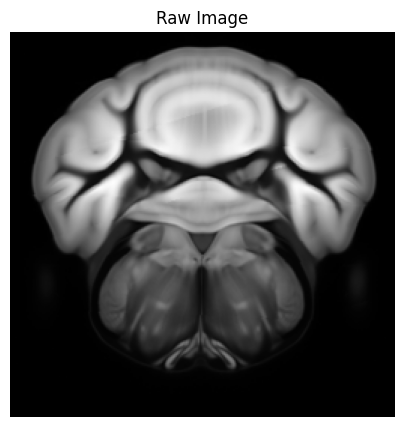

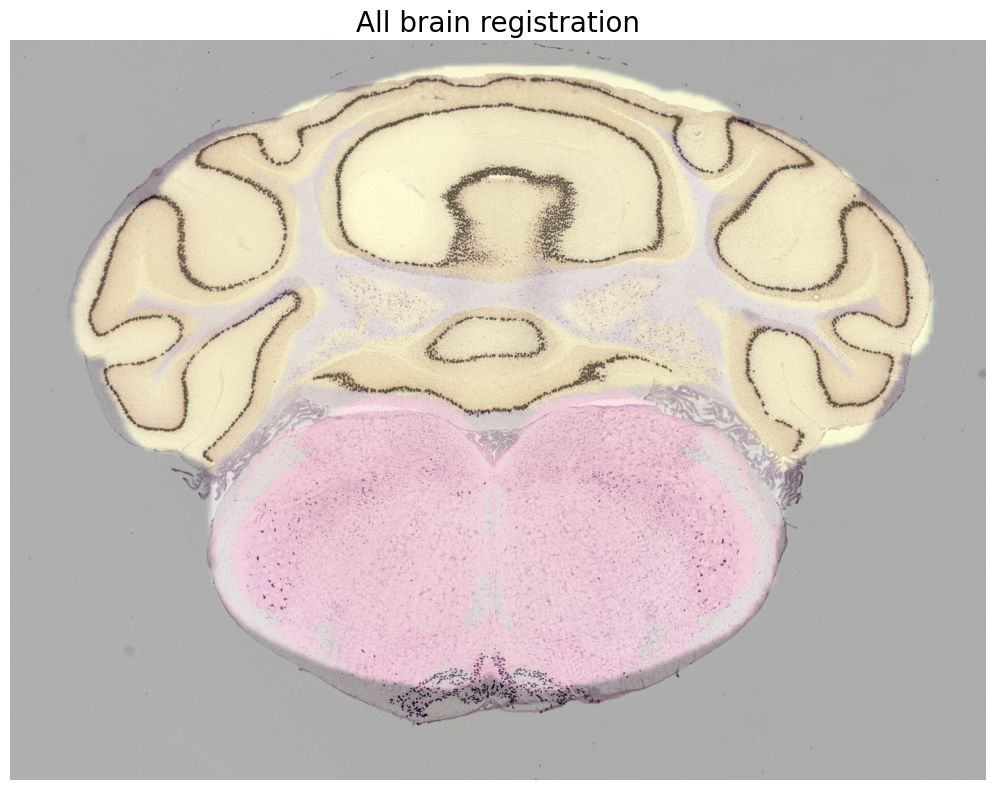

Loaded Input File (fixed): E:/benchmark/brain_image/ISH/0057_71661829.jpg
Loaded Output File (moving): E:/benchmark/brain_image/ISH/delete\resized_transformed_annotation.png


d:\Anaconda\anaconda3\envs\Brain_registration\lib\site-packages\keras\src\legacy\preprocessing\image.py:1072: UserWarning: This ImageDataGenerator specifies `samplewise_std_normalization`, which overrides setting of `samplewise_center`.
  warnings.warn(


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


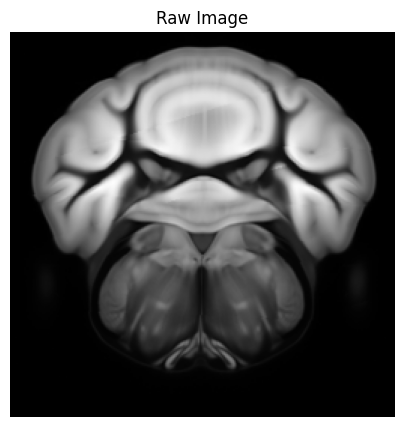

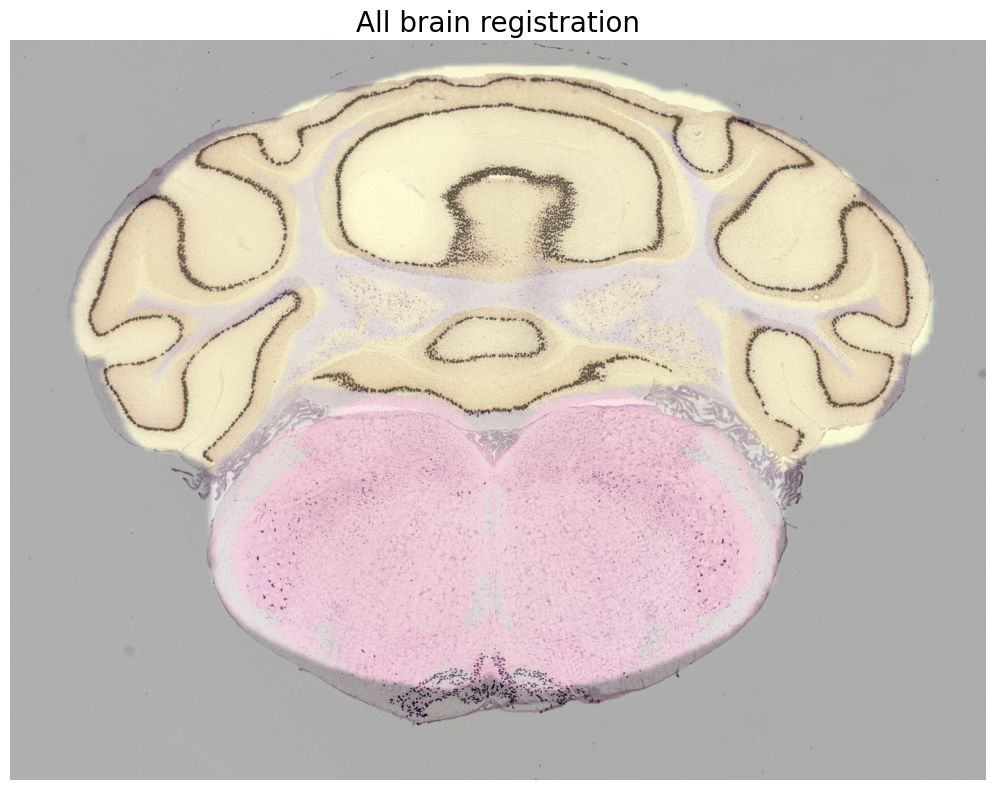

Loaded Input File (fixed): E:/benchmark/brain_image/ISH/0057_71661829.jpg
Loaded Output File (moving): E:/benchmark/brain_image/ISH/delete\resized_transformed_annotation.png


d:\Anaconda\anaconda3\envs\Brain_registration\lib\site-packages\keras\src\legacy\preprocessing\image.py:1072: UserWarning: This ImageDataGenerator specifies `samplewise_std_normalization`, which overrides setting of `samplewise_center`.
  warnings.warn(


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step


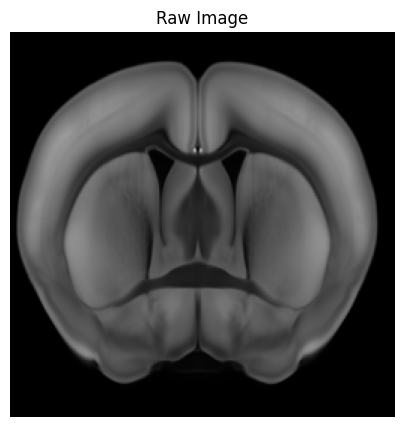

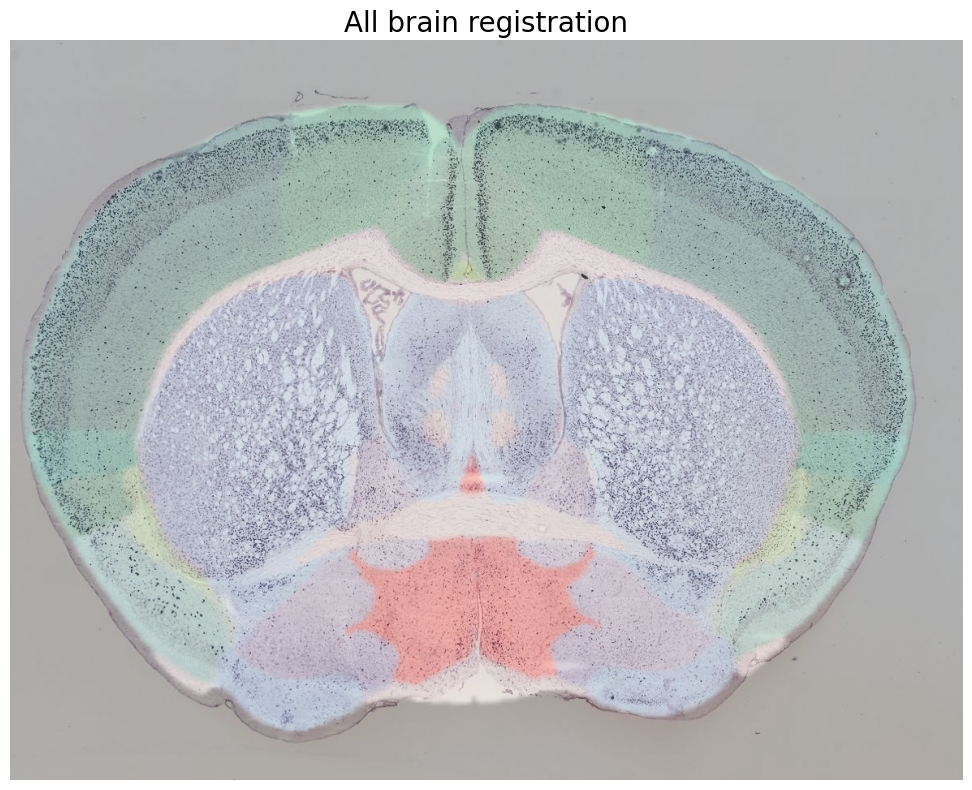

Loaded Input File (fixed): E:/benchmark/brain_image/ISH/0325_71662517.jpg
Loaded Output File (moving): E:/benchmark/brain_image/ISH/delete\resized_transformed_annotation.png


In [25]:
root = tk.Tk()
app = MainApp(root)
root.mainloop()